# Rule examples · vertical

## Setup

In [1]:
from pathlib import Path
import sys

ROOT = next(
    folder for folder in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (folder / "result_summary" / "data_helper.py").exists()
)
sys.path[:0] = [
    str(ROOT / "result_summary"),
    str(ROOT / "result_summary" / "complex_rules" / "scripts"),
    str(ROOT / "result_summary" / "differential_rules" / "scripts"),
]

import final_figures_vis as fv
import rule_examples_helper as ex
import rule_trends_helper as rt
import vis_helper as vh

In [2]:
NETWORK = False
VERTICAL = True
WIDTH = fv.PANEL_INCHES * (5 if NETWORK else 4)
DOT = 6
FONT_SIZE = 20
N_TOP = 10
ONLY_400 = True
END_COLORS = fv.stage_tags(["Control", "Severe"], 2)
END_COLORS_BY_TREND = {"Days after Transplant grouped": [END_COLORS[0], "#1B9AAA"], "Cortico Response": fv.RESPONSE_TAGS}
METRICS = ["Kind", "Support", "Confidence", "Lift", "Leverage", "Conviction", "Individual_FDR"]

## Data

In [3]:
data = ex.load()
cell_colors = vh.set_cell_colors(data.cells)

Dropped 21 FOVs: Control_S
Loaded 598093 cells; FOVs: 267, biopsies: 73, patients: 71
Read results_CN_pairwise.csv
Loaded 15660 rules.
Kept 6978 rules at FDR <= 0.05.
Kept 6946 rules naming no Unidentified.
Kept 6946 rules (max_items=2, kind=None).


c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\scr

Read results_CN_pairwise.csv


## Keys

In [4]:
if NETWORK:
    fv.save_edge_key(FONT_SIZE)

## Picking FOVs

In [5]:
def rule_examples(organ, trend, stable=False):
    """For each changing rule of the organ by `trend` (each stable one with `stable`), its two example
    FOVs by `ex.pick_examples`, drawn in one panel by `fv.plot_rule_examples` (as columns with VERTICAL)
    under their `ex.metrics`, tagged in their group's END_COLORS (or END_COLORS_BY_TREND, their key saved
    as keys/ends_<organ>_<trend>); a table of the picks."""
    picks, examples, end_colors = ex.pick_examples(
        data, organ, trend, stable, ONLY_400, END_COLORS_BY_TREND.get(trend, END_COLORS))
    fv.save_group_key(end_colors, FONT_SIZE, f"ends_{organ}_{trend.replace(' ', '_')}")
    key = fv.key_cells(data.cells, [fov for *_, sides in examples.values() for fov, *_ in sides], data.passed, N_TOP)
    folder = f"{'stable' if stable else 'rule'}_examples_{rt.LEVEL}{'_vertical' if VERTICAL else ''}"
    fv.plot_rule_examples(data.cells, examples, data.passed, cell_colors, key, width=WIDTH, font_size=FONT_SIZE,
                          network=NETWORK, vertical=VERTICAL, dot=DOT,
                          notes={name: "\n".join([name] + [ex.metrics(data, fov, rule, METRICS) for fov, *_ in sides])
                                 for name, (rule, _, sides) in examples.items()},
                          save=f"{folder}/{organ}_{trend.replace(' ', '_')}")
    return picks

## Changing rules

### Colon · Pathological score

c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\scr

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\ends_Colon_Pathological_score.pdf


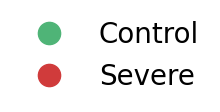

attracts_CD4T_to_Plasma
Control_Colon_04_FOV_4
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.045        0.71 1.312     0.011       1.582           0.011
GVHD_01_FOV_2_R
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Pathological_score\attracts_CD4T_to_Plasma.pdf
saved attracts_CD4T_to_Plasma_1, attracts_CD4T_to_Plasma_2, attracts_CD4T_to_Plasma_3, attracts_CD4T_to_Plasma_4, attracts_CD4T_to_Plasma_5, attracts_CD4T_to_Plasma_6, attracts_CD4T_to_Plasma_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Pathological_score


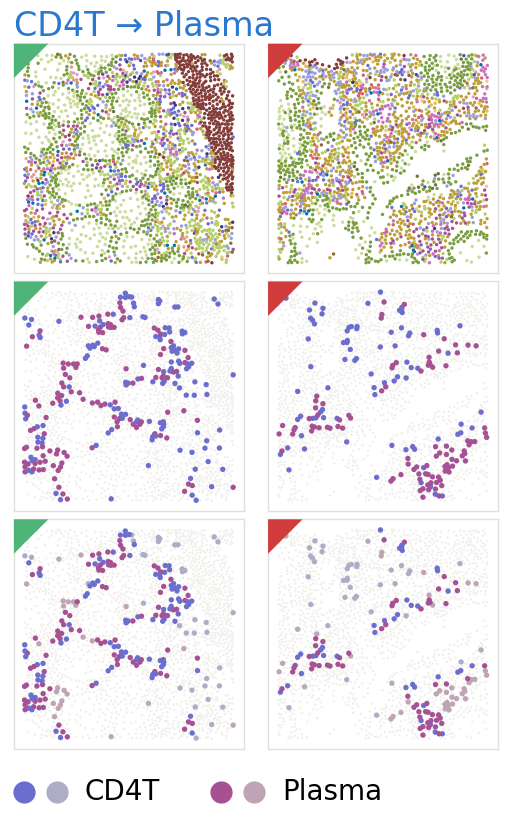

attracts_Fibroblast_to_Plasma
Control_Colon_02_FOV_2
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.134       0.865 1.218     0.024       2.148           0.002
GVHD_01_FOV_6_R
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Pathological_score\attracts_Fibroblast_to_Plasma.pdf
saved attracts_Fibroblast_to_Plasma_1, attracts_Fibroblast_to_Plasma_2, attracts_Fibroblast_to_Plasma_3, attracts_Fibroblast_to_Plasma_4, attracts_Fibroblast_to_Plasma_5, attracts_Fibroblast_to_Plasma_6, attracts_Fibroblast_to_Plasma_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Pathological_score


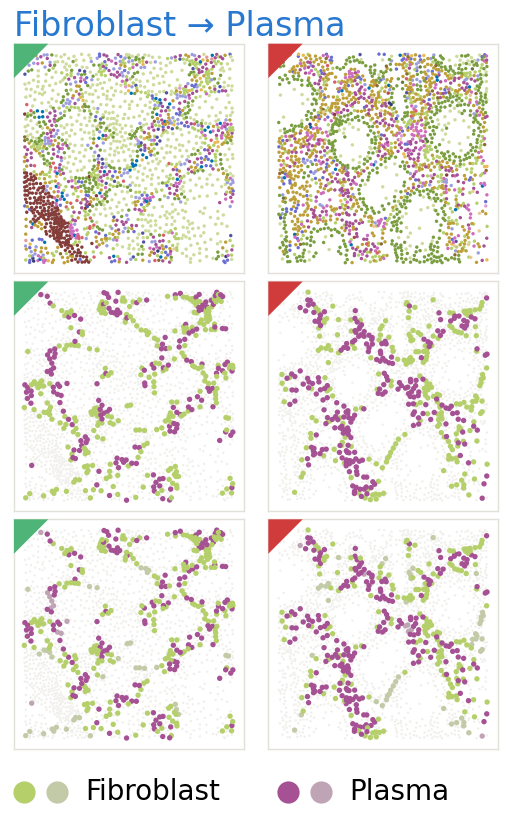

attracts_CD8T_to_Plasma
Control_Colon_02_FOV_3
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.101       0.883 1.232     0.019       2.426           0.003
GVHD_01_FOV_2_R
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Pathological_score\attracts_CD8T_to_Plasma.pdf
saved attracts_CD8T_to_Plasma_1, attracts_CD8T_to_Plasma_2, attracts_CD8T_to_Plasma_3, attracts_CD8T_to_Plasma_4, attracts_CD8T_to_Plasma_5, attracts_CD8T_to_Plasma_6, attracts_CD8T_to_Plasma_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Pathological_score


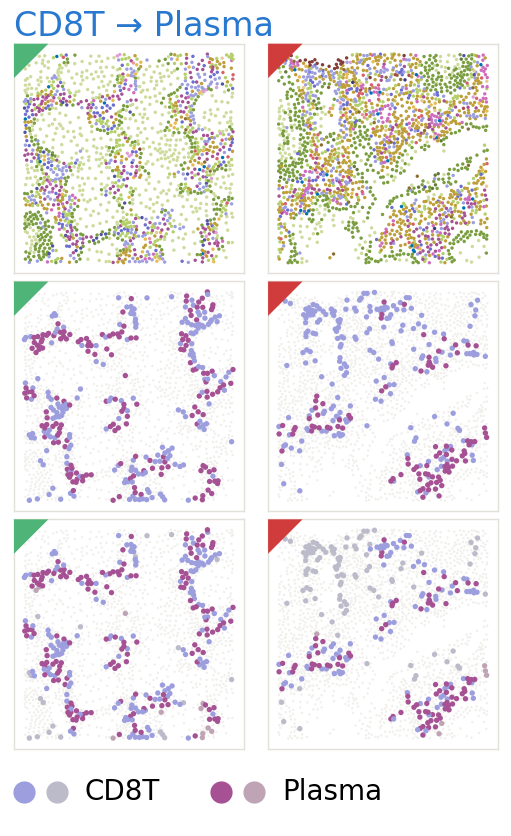

attracts_Macrophage_to_Plasma
Control_Colon_01_FOV_1
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.126       0.897 1.205     0.021       2.488           0.004
GVHD_01_FOV_6_R
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Pathological_score\attracts_Macrophage_to_Plasma.pdf
saved attracts_Macrophage_to_Plasma_1, attracts_Macrophage_to_Plasma_2, attracts_Macrophage_to_Plasma_3, attracts_Macrophage_to_Plasma_4, attracts_Macrophage_to_Plasma_5, attracts_Macrophage_to_Plasma_6, attracts_Macrophage_to_Plasma_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Pathological_score


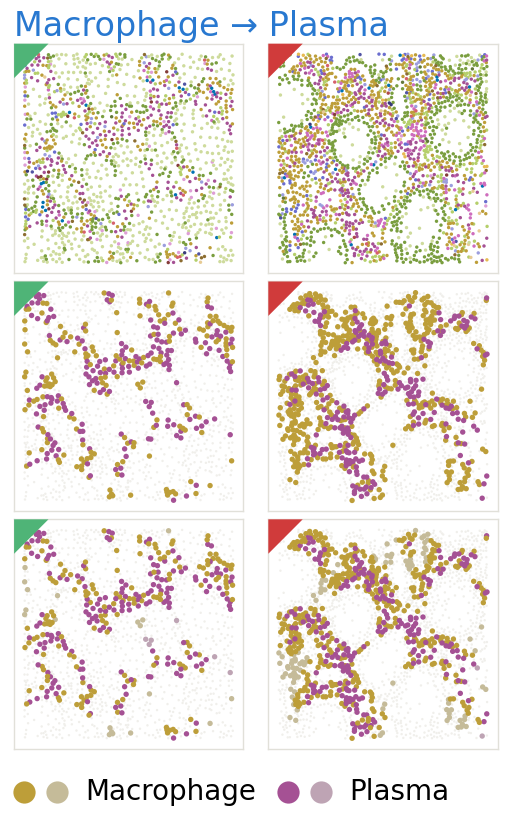

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Pathological_score\cells.pdf


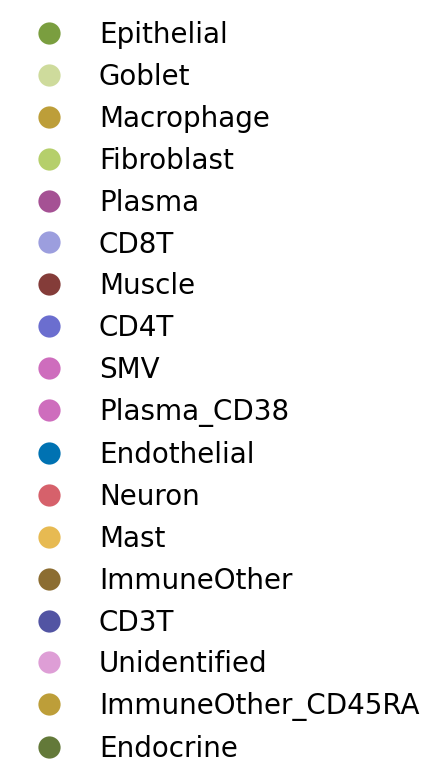

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,attracts,CD4T -> Plasma,Control,True,Control_Colon_04_FOV_4,122
1,attracts,CD4T -> Plasma,Severe,False,GVHD_01_FOV_2_R,80
2,attracts,Fibroblast -> Plasma,Control,True,Control_Colon_02_FOV_2,166
3,attracts,Fibroblast -> Plasma,Severe,False,GVHD_01_FOV_6_R,228
4,attracts,CD8T -> Plasma,Control,True,Control_Colon_02_FOV_3,168
5,attracts,CD8T -> Plasma,Severe,False,GVHD_01_FOV_2_R,96
6,attracts,Macrophage -> Plasma,Control,True,Control_Colon_01_FOV_1,181
7,attracts,Macrophage -> Plasma,Severe,False,GVHD_01_FOV_6_R,228


In [6]:
rule_examples("Colon", "Pathological score")

### Colon · Clinical score

c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\scr

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\ends_Colon_Clinical_score.pdf


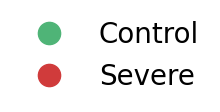

attracts_CD4T_to_Plasma
Control_Colon_04_FOV_4
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.045        0.71 1.312     0.011       1.582           0.011
GVHD_01_FOV_2_R
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Clinical_score\attracts_CD4T_to_Plasma.pdf
saved attracts_CD4T_to_Plasma_1, attracts_CD4T_to_Plasma_2, attracts_CD4T_to_Plasma_3, attracts_CD4T_to_Plasma_4, attracts_CD4T_to_Plasma_5, attracts_CD4T_to_Plasma_6, attracts_CD4T_to_Plasma_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Clinical_score


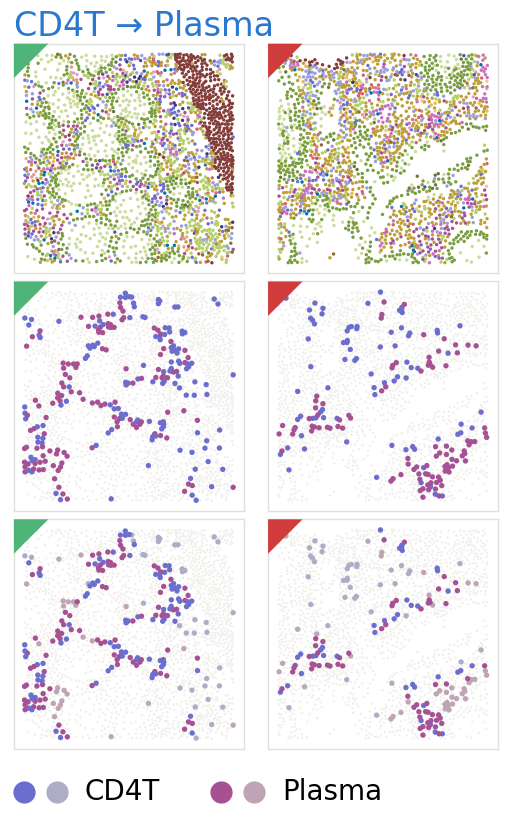

attracts_Macrophage_to_Plasma
Control_Colon_01_FOV_1
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.126       0.897 1.205     0.021       2.488           0.004
GVHD_01_FOV_6_R
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Clinical_score\attracts_Macrophage_to_Plasma.pdf
saved attracts_Macrophage_to_Plasma_1, attracts_Macrophage_to_Plasma_2, attracts_Macrophage_to_Plasma_3, attracts_Macrophage_to_Plasma_4, attracts_Macrophage_to_Plasma_5, attracts_Macrophage_to_Plasma_6, attracts_Macrophage_to_Plasma_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Clinical_score


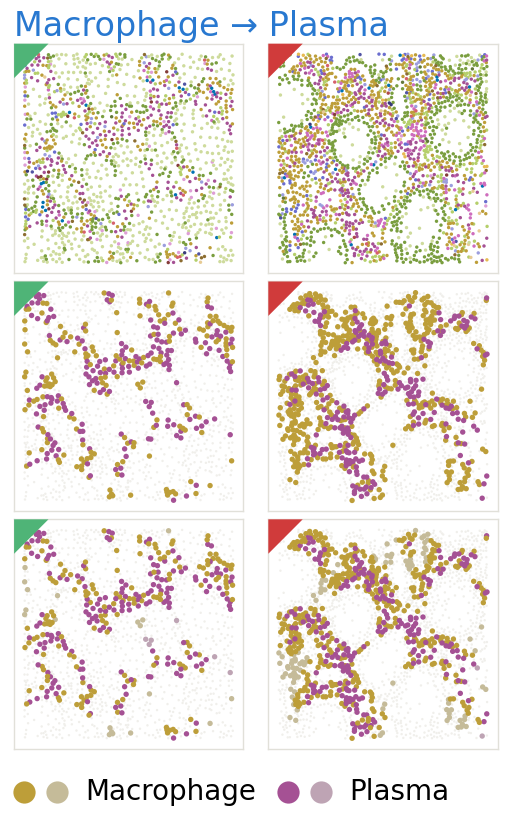

attracts_Fibroblast_to_Plasma
Control_Colon_02_FOV_2
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.134       0.865 1.218     0.024       2.148           0.002
GVHD_01_FOV_6_R
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Clinical_score\attracts_Fibroblast_to_Plasma.pdf
saved attracts_Fibroblast_to_Plasma_1, attracts_Fibroblast_to_Plasma_2, attracts_Fibroblast_to_Plasma_3, attracts_Fibroblast_to_Plasma_4, attracts_Fibroblast_to_Plasma_5, attracts_Fibroblast_to_Plasma_6, attracts_Fibroblast_to_Plasma_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Clinical_score


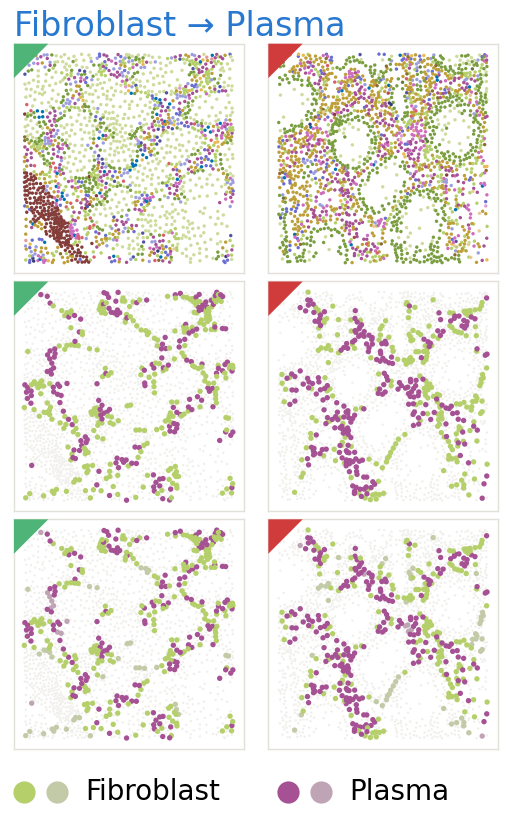

attracts_CD8T_to_Plasma
Control_Colon_02_FOV_3
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.101       0.883 1.232     0.019       2.426           0.003
GVHD_01_FOV_2_R
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Clinical_score\attracts_CD8T_to_Plasma.pdf
saved attracts_CD8T_to_Plasma_1, attracts_CD8T_to_Plasma_2, attracts_CD8T_to_Plasma_3, attracts_CD8T_to_Plasma_4, attracts_CD8T_to_Plasma_5, attracts_CD8T_to_Plasma_6, attracts_CD8T_to_Plasma_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Clinical_score


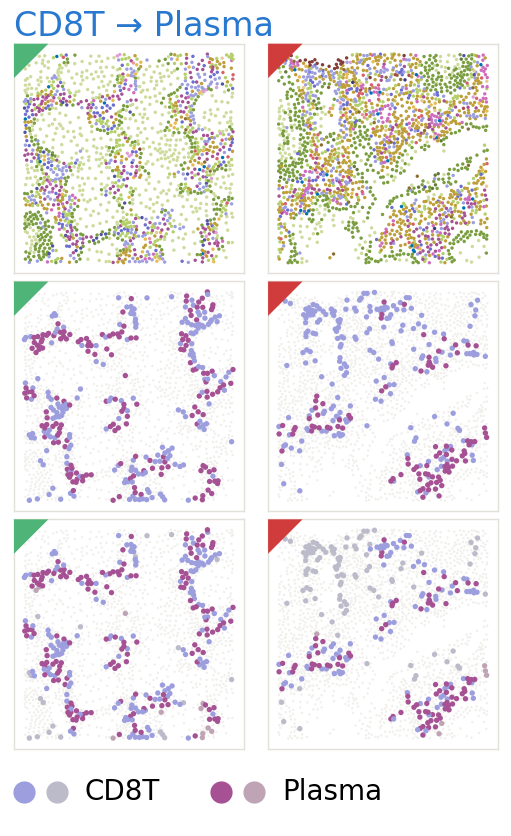

avoids_Goblet_to_Mast
Control_Colon_03_FOV_1
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.055       0.281 0.564    -0.042       0.698           0.002
GVHD_01_FOV_2_R
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.001       0.015 0.055    -0.017        0.74           0.267
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Clinical_score\avoids_Goblet_to_Mast.pdf
saved avoids_Goblet_to_Mast_1, avoids_Goblet_to_Mast_2, avoids_Goblet_to_Mast_3, avoids_Goblet_to_Mast_4, avoids_Goblet_to_Mast_5, avoids_Goblet_to_Mast_6, avoids_Goblet_to_Mast_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Clinical_score


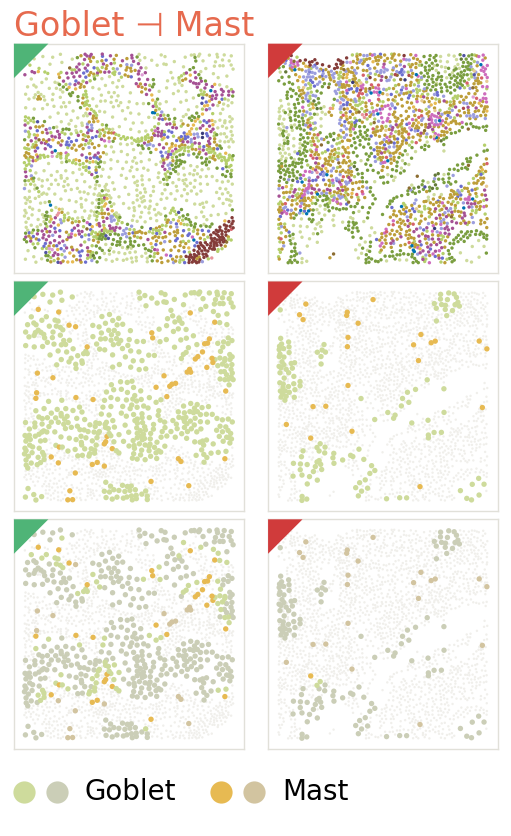

avoids_Goblet_to_Endothelial
Control_Colon_02_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.049       0.203 0.523    -0.045       0.767           0.002
GVHD_32_FOV_4
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.008       0.076 0.257    -0.023       0.763           0.053
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Clinical_score\avoids_Goblet_to_Endothelial.pdf


c:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\final_figures_vis.py:103: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(folder / f"{name}.pdf", bbox_inches=box.transformed(fig.dpi_scale_trans.inverted()))
c:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\final_figures_vis.py:103: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(folder / f"{name}.pdf", bbox_inches=box.transformed(fig.dpi_scale_trans.inverted()))
c:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\final_figures_vis.py:103: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(folder / f"{name}.pdf", bbox_inches=box.transformed(fig.dpi_scale_trans.inverted

saved avoids_Goblet_to_Endothelial_1, avoids_Goblet_to_Endothelial_2, avoids_Goblet_to_Endothelial_3, avoids_Goblet_to_Endothelial_4, avoids_Goblet_to_Endothelial_5, avoids_Goblet_to_Endothelial_6, avoids_Goblet_to_Endothelial_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Clinical_score


c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


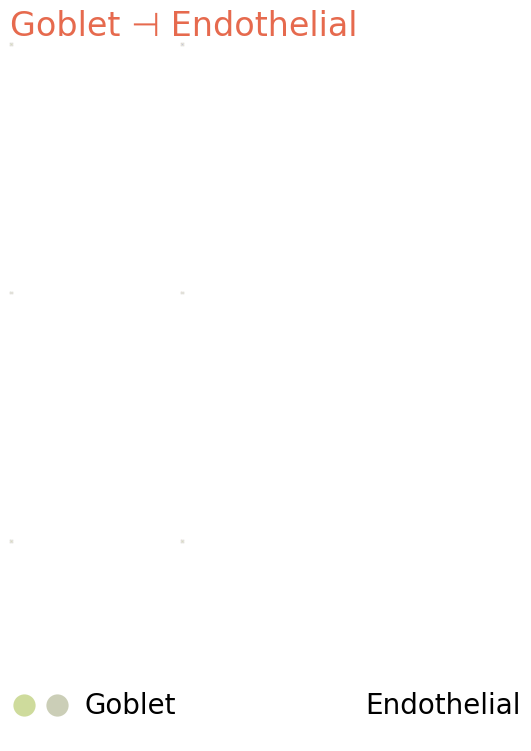

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Clinical_score\cells.pdf


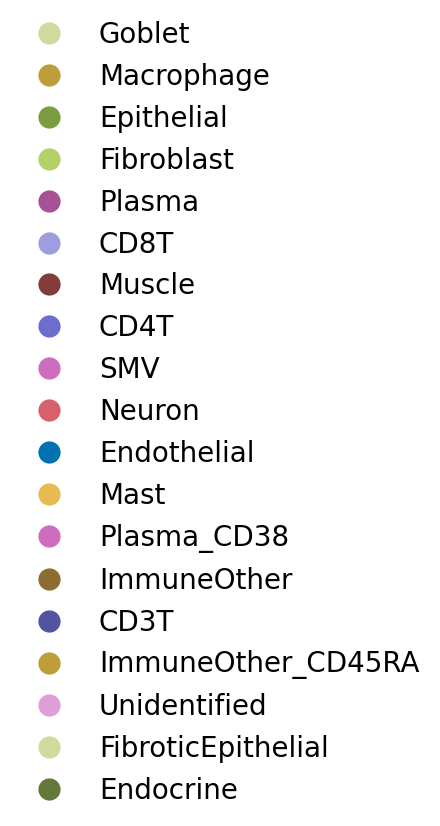

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,attracts,CD4T -> Plasma,Control,True,Control_Colon_04_FOV_4,122
1,attracts,CD4T -> Plasma,Severe,False,GVHD_01_FOV_2_R,80
2,attracts,Macrophage -> Plasma,Control,True,Control_Colon_01_FOV_1,181
3,attracts,Macrophage -> Plasma,Severe,False,GVHD_01_FOV_6_R,228
4,attracts,Fibroblast -> Plasma,Control,True,Control_Colon_02_FOV_2,166
5,attracts,Fibroblast -> Plasma,Severe,False,GVHD_01_FOV_6_R,228
6,attracts,CD8T -> Plasma,Control,True,Control_Colon_02_FOV_3,168
7,attracts,CD8T -> Plasma,Severe,False,GVHD_01_FOV_2_R,96
8,avoids,Goblet -> Mast,Control,True,Control_Colon_03_FOV_1,53
9,avoids,Goblet -> Mast,Severe,False,GVHD_01_FOV_2_R,24


In [7]:
rule_examples("Colon", "Clinical score")

### Colon · Pathological stage

c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\scr

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\ends_Colon_Pathological_stage.pdf


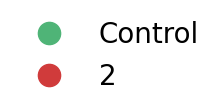

avoids_Fibroblast_to_Goblet
Control_Colon_03_FOV_2
not mined in this FOV
GVHD_21_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.063       0.324 0.529    -0.056       0.574           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Pathological_stage\avoids_Fibroblast_to_Goblet.pdf
saved avoids_Fibroblast_to_Goblet_1, avoids_Fibroblast_to_Goblet_2, avoids_Fibroblast_to_Goblet_3, avoids_Fibroblast_to_Goblet_4, avoids_Fibroblast_to_Goblet_5, avoids_Fibroblast_to_Goblet_6, avoids_Fibroblast_to_Goblet_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Pathological_stage


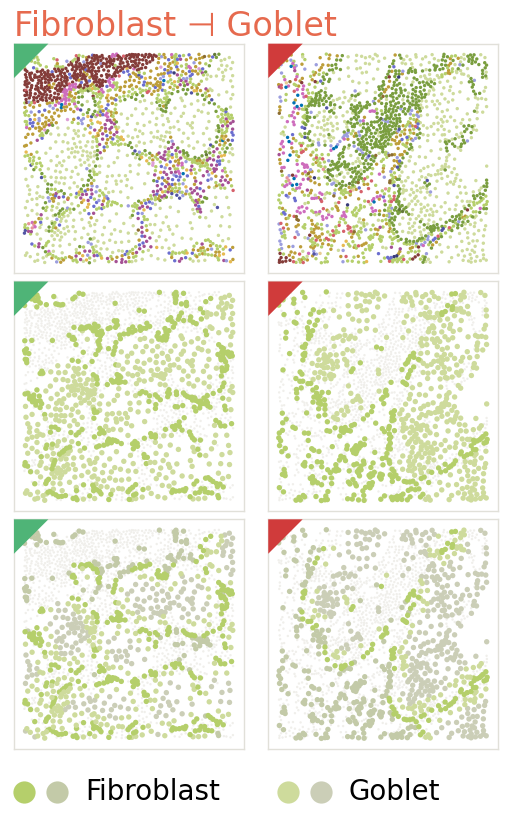

avoids_Goblet_to_Endothelial
Control_Colon_02_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.049       0.203 0.523    -0.045       0.767           0.002
GVHD_32_FOV_4
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.008       0.076 0.257    -0.023       0.763           0.053
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Pathological_stage\avoids_Goblet_to_Endothelial.pdf


c:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\final_figures_vis.py:103: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(folder / f"{name}.pdf", bbox_inches=box.transformed(fig.dpi_scale_trans.inverted()))
c:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\final_figures_vis.py:103: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(folder / f"{name}.pdf", bbox_inches=box.transformed(fig.dpi_scale_trans.inverted()))
c:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\final_figures_vis.py:103: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(folder / f"{name}.pdf", bbox_inches=box.transformed(fig.dpi_scale_trans.inverted

saved avoids_Goblet_to_Endothelial_1, avoids_Goblet_to_Endothelial_2, avoids_Goblet_to_Endothelial_3, avoids_Goblet_to_Endothelial_4, avoids_Goblet_to_Endothelial_5, avoids_Goblet_to_Endothelial_6, avoids_Goblet_to_Endothelial_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Pathological_stage


c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


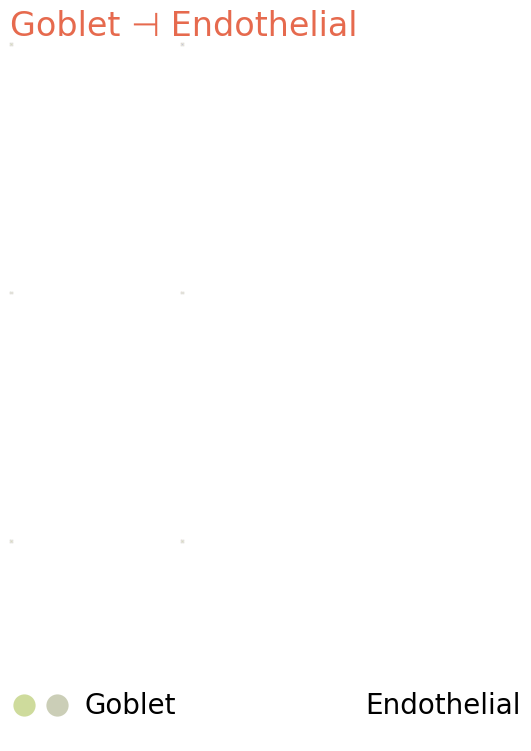

avoids_Goblet_to_CD4T
Control_Colon_04_FOV_1
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.022        0.17  0.29    -0.054       0.499           0.003
GVHD_01_FOV_1
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.007       0.107 0.299    -0.017       0.721           0.058
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Pathological_stage\avoids_Goblet_to_CD4T.pdf
saved avoids_Goblet_to_CD4T_1, avoids_Goblet_to_CD4T_2, avoids_Goblet_to_CD4T_3, avoids_Goblet_to_CD4T_4, avoids_Goblet_to_CD4T_5, avoids_Goblet_to_CD4T_6, avoids_Goblet_to_CD4T_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Pathological_stage


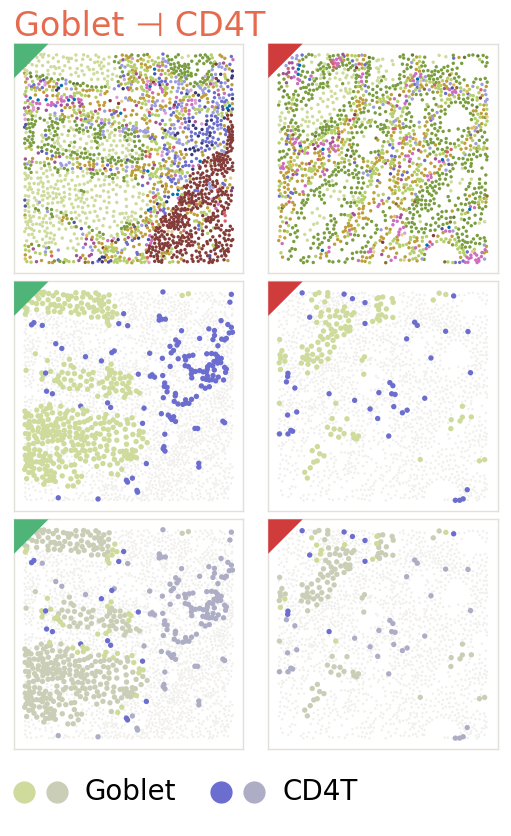

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Pathological_stage\cells.pdf


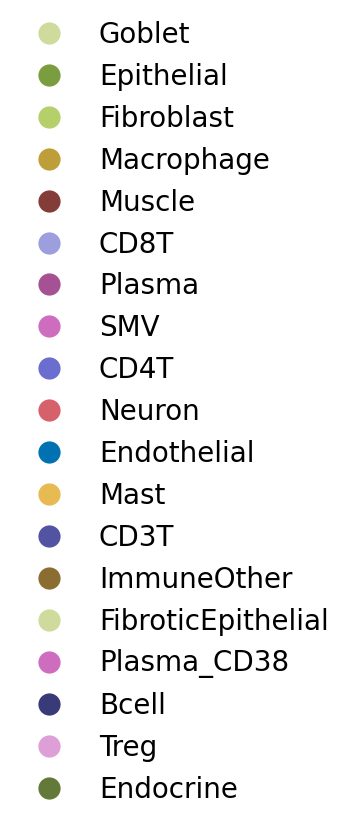

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,avoids,Fibroblast -> Goblet,Control,False,Control_Colon_03_FOV_2,379
1,avoids,Fibroblast -> Goblet,2,True,GVHD_21_FOV_2,327
2,avoids,Goblet -> Endothelial,Control,True,Control_Colon_02_FOV_2,44
3,avoids,Goblet -> Endothelial,2,False,GVHD_32_FOV_4,31
4,avoids,Goblet -> CD4T,Control,True,Control_Colon_04_FOV_1,138
5,avoids,Goblet -> CD4T,2,False,GVHD_01_FOV_1,42


In [8]:
rule_examples("Colon", "Pathological stage")

### Colon · GI stage

c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\scr

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\ends_Colon_GI_stage.pdf


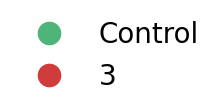

avoids_Goblet_to_Fibroblast
Control_Colon_04_FOV_1
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.056       0.432 0.535    -0.049       0.339           0.003
GVHD_37_FOV_2
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_GI_stage\avoids_Goblet_to_Fibroblast.pdf
saved avoids_Goblet_to_Fibroblast_1, avoids_Goblet_to_Fibroblast_2, avoids_Goblet_to_Fibroblast_3, avoids_Goblet_to_Fibroblast_4, avoids_Goblet_to_Fibroblast_5, avoids_Goblet_to_Fibroblast_6, avoids_Goblet_to_Fibroblast_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_GI_stage


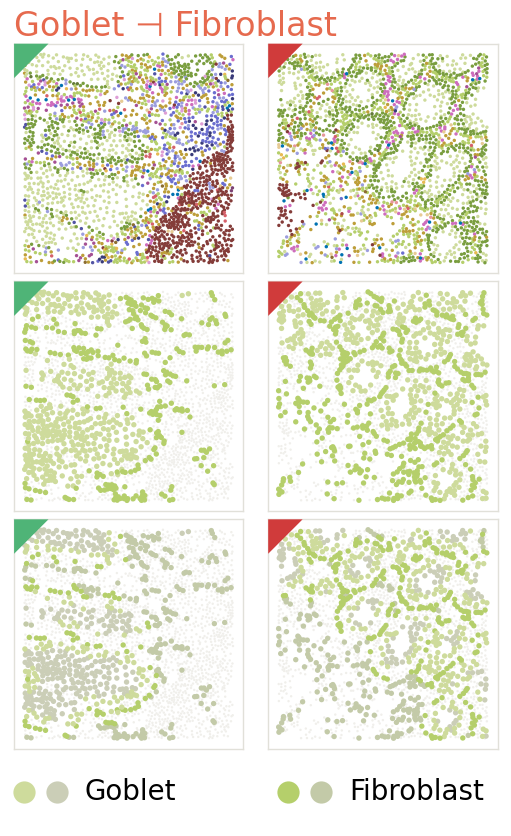

avoids_Goblet_to_CD8T
Control_Colon_04_FOV_1
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.053       0.405 0.642    -0.029        0.62           0.003
GVHD_22_FOV_1
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_GI_stage\avoids_Goblet_to_CD8T.pdf
saved avoids_Goblet_to_CD8T_1, avoids_Goblet_to_CD8T_2, avoids_Goblet_to_CD8T_3, avoids_Goblet_to_CD8T_4, avoids_Goblet_to_CD8T_5, avoids_Goblet_to_CD8T_6, avoids_Goblet_to_CD8T_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_GI_stage


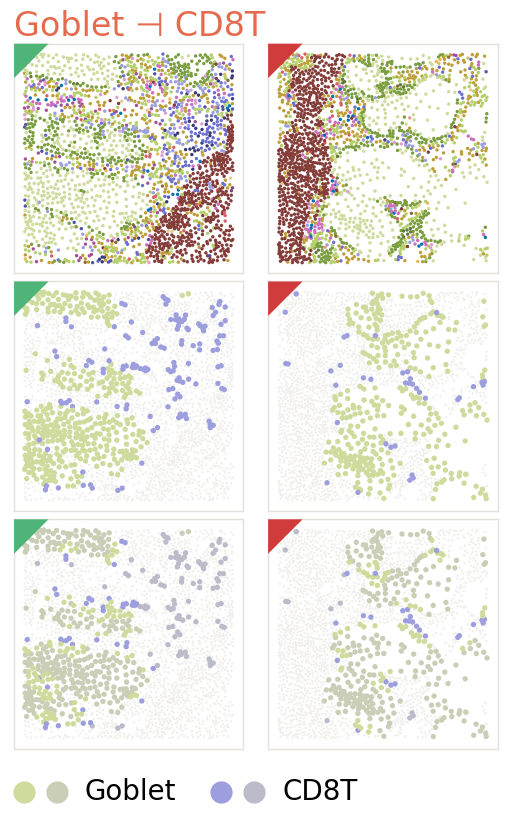

avoids_Goblet_to_Endothelial
Control_Colon_02_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.049       0.203 0.523    -0.045       0.767           0.002
GVHD_37_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.007       0.042 0.174    -0.034       0.794           0.121
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_GI_stage\avoids_Goblet_to_Endothelial.pdf


c:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\final_figures_vis.py:103: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(folder / f"{name}.pdf", bbox_inches=box.transformed(fig.dpi_scale_trans.inverted()))
c:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\final_figures_vis.py:103: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(folder / f"{name}.pdf", bbox_inches=box.transformed(fig.dpi_scale_trans.inverted()))
c:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\final_figures_vis.py:103: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(folder / f"{name}.pdf", bbox_inches=box.transformed(fig.dpi_scale_trans.inverted

saved avoids_Goblet_to_Endothelial_1, avoids_Goblet_to_Endothelial_2, avoids_Goblet_to_Endothelial_3, avoids_Goblet_to_Endothelial_4, avoids_Goblet_to_Endothelial_5, avoids_Goblet_to_Endothelial_6, avoids_Goblet_to_Endothelial_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_GI_stage


c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


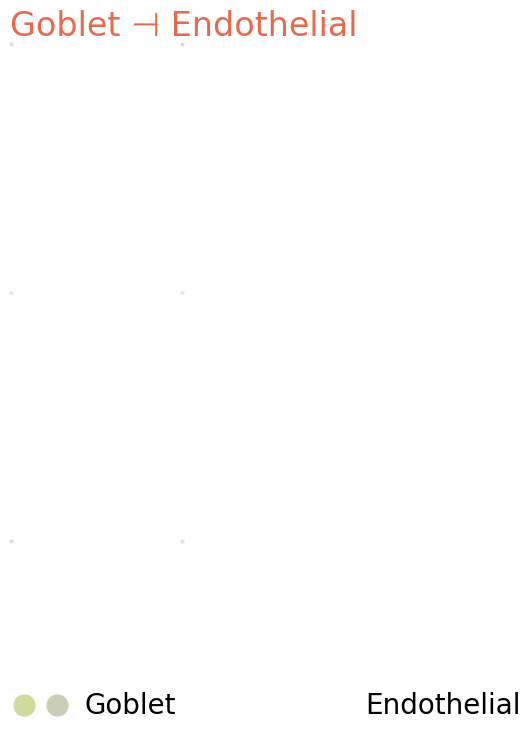

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_GI_stage\cells.pdf


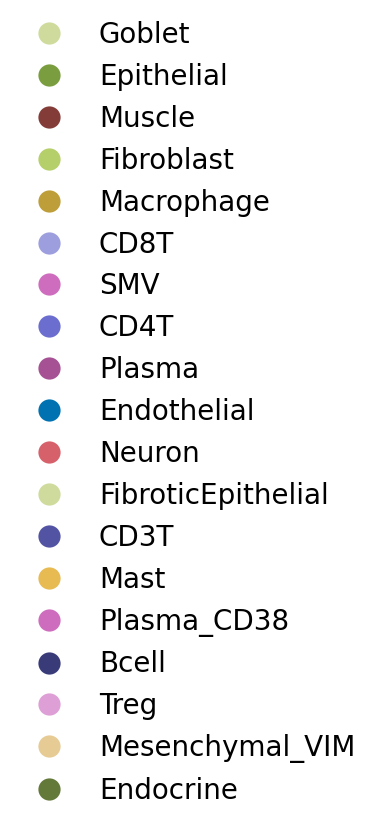

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,avoids,Goblet -> Fibroblast,Control,True,Control_Colon_04_FOV_1,300
1,avoids,Goblet -> Fibroblast,3,False,GVHD_37_FOV_2,376
2,avoids,Goblet -> CD8T,Control,True,Control_Colon_04_FOV_1,135
3,avoids,Goblet -> CD8T,3,False,GVHD_22_FOV_1,37
4,avoids,Goblet -> Endothelial,Control,True,Control_Colon_02_FOV_2,44
5,avoids,Goblet -> Endothelial,3,False,GVHD_37_FOV_2,26


In [9]:
rule_examples("Colon", "GI stage")

### Colon · Days after Transplant grouped

c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\scr

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\ends_Colon_Days_after_Transplant_grouped.pdf


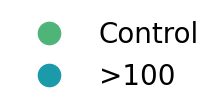

attracts_Macrophage_to_Plasma
Control_Colon_01_FOV_1
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.126       0.897 1.205     0.021       2.488           0.004
GVHD_25_FOV_2
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Days_after_Transplant_grouped\attracts_Macrophage_to_Plasma.pdf
saved attracts_Macrophage_to_Plasma_1, attracts_Macrophage_to_Plasma_2, attracts_Macrophage_to_Plasma_3, attracts_Macrophage_to_Plasma_4, attracts_Macrophage_to_Plasma_5, attracts_Macrophage_to_Plasma_6, attracts_Macrophage_to_Plasma_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Days_after_Transplant_grouped


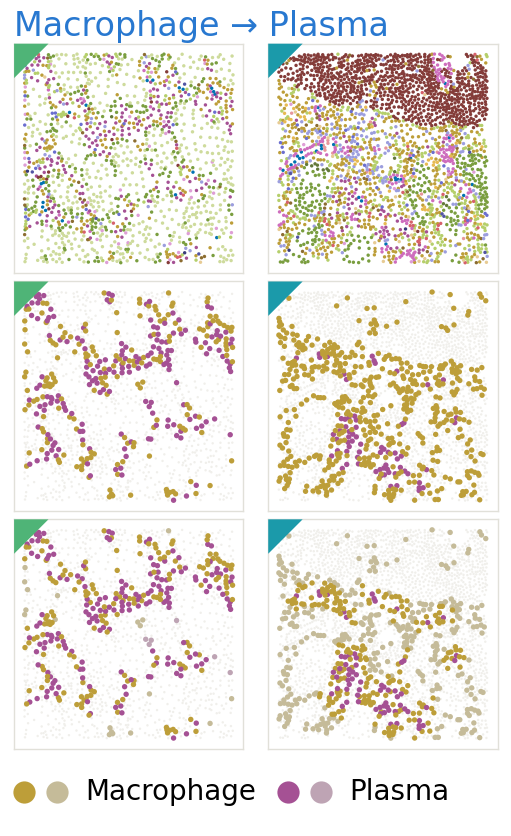

attracts_CD4T_to_Plasma
Control_Colon_04_FOV_4
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.045        0.71 1.312     0.011       1.582           0.011
GVHD_25_FOV_3
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Days_after_Transplant_grouped\attracts_CD4T_to_Plasma.pdf
saved attracts_CD4T_to_Plasma_1, attracts_CD4T_to_Plasma_2, attracts_CD4T_to_Plasma_3, attracts_CD4T_to_Plasma_4, attracts_CD4T_to_Plasma_5, attracts_CD4T_to_Plasma_6, attracts_CD4T_to_Plasma_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Days_after_Transplant_grouped


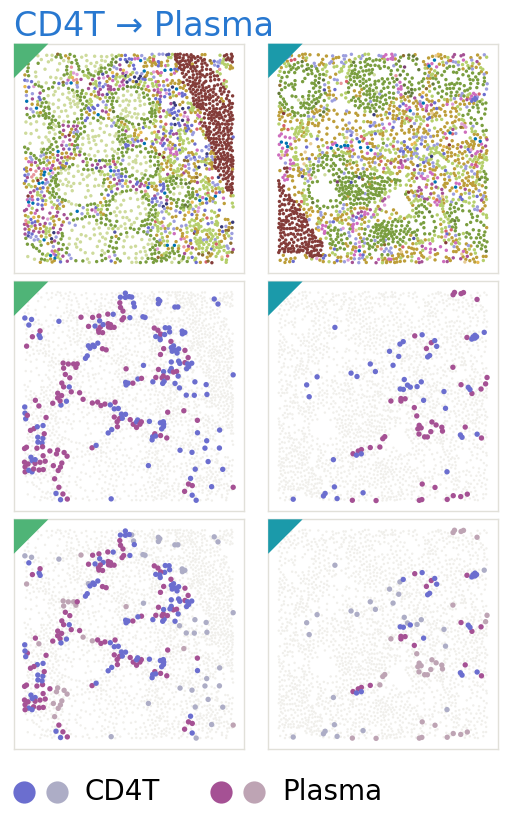

attracts_Fibroblast_to_Plasma
Control_Colon_02_FOV_2
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.134       0.865 1.218     0.024       2.148           0.002
GVHD_25_FOV_2
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Days_after_Transplant_grouped\attracts_Fibroblast_to_Plasma.pdf
saved attracts_Fibroblast_to_Plasma_1, attracts_Fibroblast_to_Plasma_2, attracts_Fibroblast_to_Plasma_3, attracts_Fibroblast_to_Plasma_4, attracts_Fibroblast_to_Plasma_5, attracts_Fibroblast_to_Plasma_6, attracts_Fibroblast_to_Plasma_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Days_after_Transplant_grouped


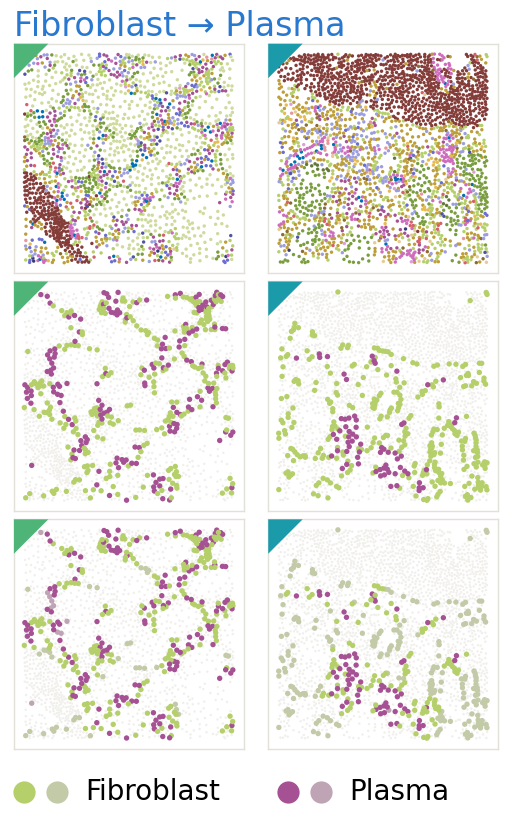

attracts_Fibroblast_to_Neuron
Control_Colon_01_FOV_4
not mined in this FOV
GVHD_13_FOV_2
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.108       0.649  1.28     0.024       1.404           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Days_after_Transplant_grouped\attracts_Fibroblast_to_Neuron.pdf
saved attracts_Fibroblast_to_Neuron_1, attracts_Fibroblast_to_Neuron_2, attracts_Fibroblast_to_Neuron_3, attracts_Fibroblast_to_Neuron_4, attracts_Fibroblast_to_Neuron_5, attracts_Fibroblast_to_Neuron_6, attracts_Fibroblast_to_Neuron_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Days_after_Transplant_grouped


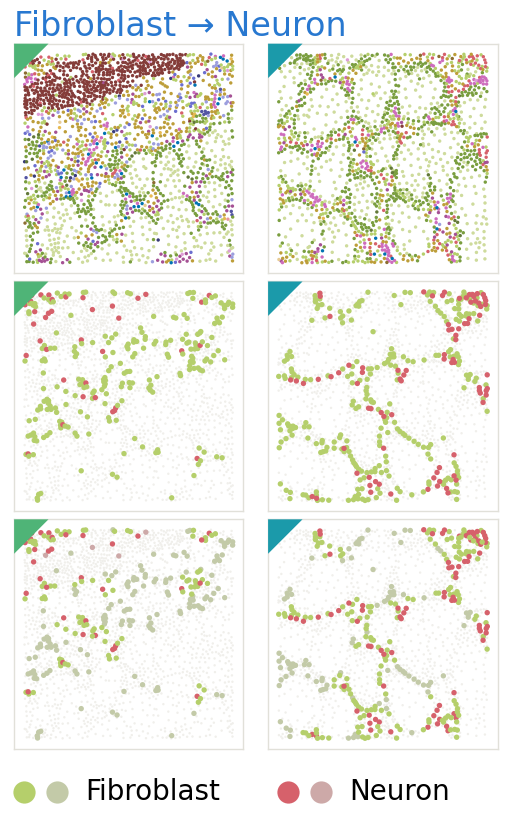

avoids_Goblet_to_Endothelial
Control_Colon_02_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.049       0.203 0.523    -0.045       0.767           0.002
GVHD_32_FOV_4
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.008       0.076 0.257    -0.023       0.763           0.053
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Days_after_Transplant_grouped\avoids_Goblet_to_Endothelial.pdf


c:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\final_figures_vis.py:103: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(folder / f"{name}.pdf", bbox_inches=box.transformed(fig.dpi_scale_trans.inverted()))
c:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\final_figures_vis.py:103: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(folder / f"{name}.pdf", bbox_inches=box.transformed(fig.dpi_scale_trans.inverted()))
c:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\final_figures_vis.py:103: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(folder / f"{name}.pdf", bbox_inches=box.transformed(fig.dpi_scale_trans.inverted

saved avoids_Goblet_to_Endothelial_1, avoids_Goblet_to_Endothelial_2, avoids_Goblet_to_Endothelial_3, avoids_Goblet_to_Endothelial_4, avoids_Goblet_to_Endothelial_5, avoids_Goblet_to_Endothelial_6, avoids_Goblet_to_Endothelial_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Days_after_Transplant_grouped


c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


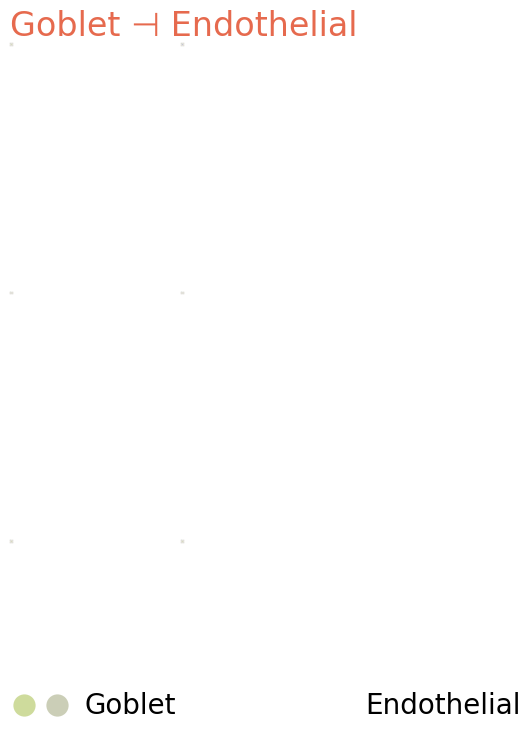

avoids_Goblet_to_Neuron
Control_Colon_04_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.007       0.069 0.251     -0.02       0.778           0.068
GVHD_13_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.048       0.209 0.413    -0.069       0.623           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Days_after_Transplant_grouped\avoids_Goblet_to_Neuron.pdf
saved avoids_Goblet_to_Neuron_1, avoids_Goblet_to_Neuron_2, avoids_Goblet_to_Neuron_3, avoids_Goblet_to_Neuron_4, avoids_Goblet_to_Neuron_5, avoids_Goblet_to_Neuron_6, avoids_Goblet_to_Neuron_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Days_after_Transplant_grouped


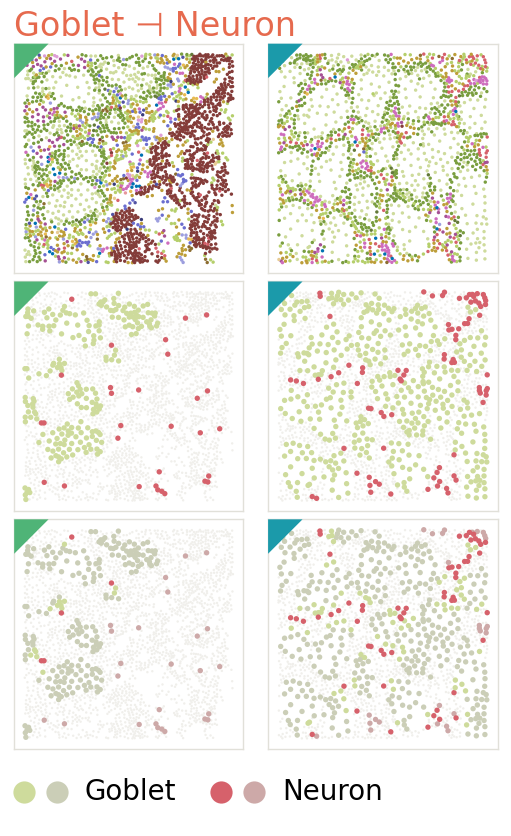

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Colon_Days_after_Transplant_grouped\cells.pdf


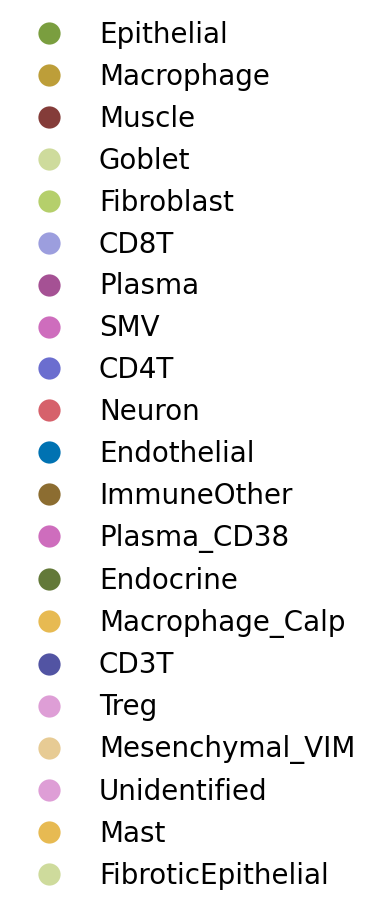

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,attracts,Macrophage -> Plasma,Control,True,Control_Colon_01_FOV_1,181
1,attracts,Macrophage -> Plasma,>100,False,GVHD_25_FOV_2,68
2,attracts,CD4T -> Plasma,Control,True,Control_Colon_04_FOV_4,122
3,attracts,CD4T -> Plasma,>100,False,GVHD_25_FOV_3,49
4,attracts,Fibroblast -> Plasma,Control,True,Control_Colon_02_FOV_2,166
5,attracts,Fibroblast -> Plasma,>100,False,GVHD_25_FOV_2,68
6,attracts,Fibroblast -> Neuron,Control,False,Control_Colon_01_FOV_4,37
7,attracts,Fibroblast -> Neuron,>100,True,GVHD_13_FOV_2,86
8,avoids,Goblet -> Endothelial,Control,True,Control_Colon_02_FOV_2,44
9,avoids,Goblet -> Endothelial,>100,False,GVHD_32_FOV_4,31


In [10]:
rule_examples("Colon", "Days after Transplant grouped")

### Duodenum · Pathological stage

c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\scr

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\ends_Duodenum_Pathological_stage.pdf


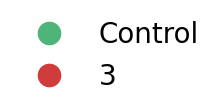

attracts_Plasma_to_Plasma_CD38
Control_10_FOV_4
not mined in this FOV
GVHD_26_FOV_4
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.038        0.94  1.38      0.01       5.296           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Duodenum_Pathological_stage\attracts_Plasma_to_Plasma_CD38.pdf


c:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\final_figures_vis.py:103: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(folder / f"{name}.pdf", bbox_inches=box.transformed(fig.dpi_scale_trans.inverted()))
c:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\final_figures_vis.py:103: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(folder / f"{name}.pdf", bbox_inches=box.transformed(fig.dpi_scale_trans.inverted()))
c:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\final_figures_vis.py:103: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(folder / f"{name}.pdf", bbox_inches=box.transformed(fig.dpi_scale_trans.inverted

saved attracts_Plasma_to_Plasma_CD38_1, attracts_Plasma_to_Plasma_CD38_2, attracts_Plasma_to_Plasma_CD38_3, attracts_Plasma_to_Plasma_CD38_4, attracts_Plasma_to_Plasma_CD38_5, attracts_Plasma_to_Plasma_CD38_6, attracts_Plasma_to_Plasma_CD38_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Duodenum_Pathological_stage


c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


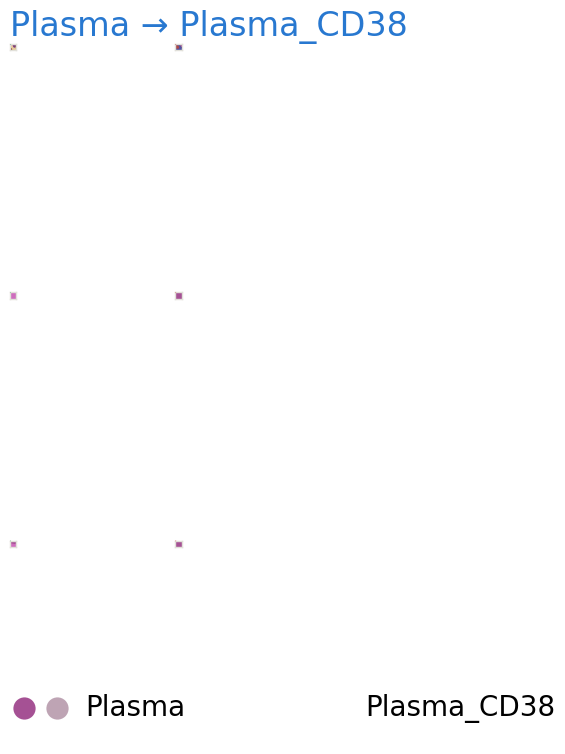

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Duodenum_Pathological_stage\cells.pdf


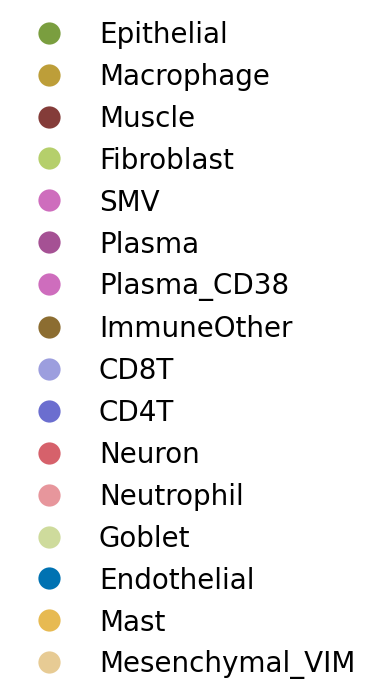

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,attracts,Plasma -> Plasma_CD38,Control,False,Control_10_FOV_4,95
1,attracts,Plasma -> Plasma_CD38,3,True,GVHD_26_FOV_4,83


In [11]:
rule_examples("Duodenum", "Pathological stage")

### Duodenum · Cortico Response

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\ends_Duodenum_Cortico_Response.pdf


c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\scr

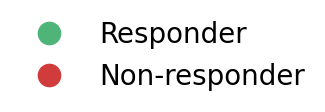

attracts_SMV_to_Fibroblast
GVHD_30_FOV_2
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.106       0.947 1.274     0.023       4.856           0.004
GVHD_06_FOV_5
not mined in this FOV
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Duodenum_Cortico_Response\attracts_SMV_to_Fibroblast.pdf
saved attracts_SMV_to_Fibroblast_1, attracts_SMV_to_Fibroblast_2, attracts_SMV_to_Fibroblast_3, attracts_SMV_to_Fibroblast_4, attracts_SMV_to_Fibroblast_5, attracts_SMV_to_Fibroblast_6, attracts_SMV_to_Fibroblast_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Duodenum_Cortico_Response


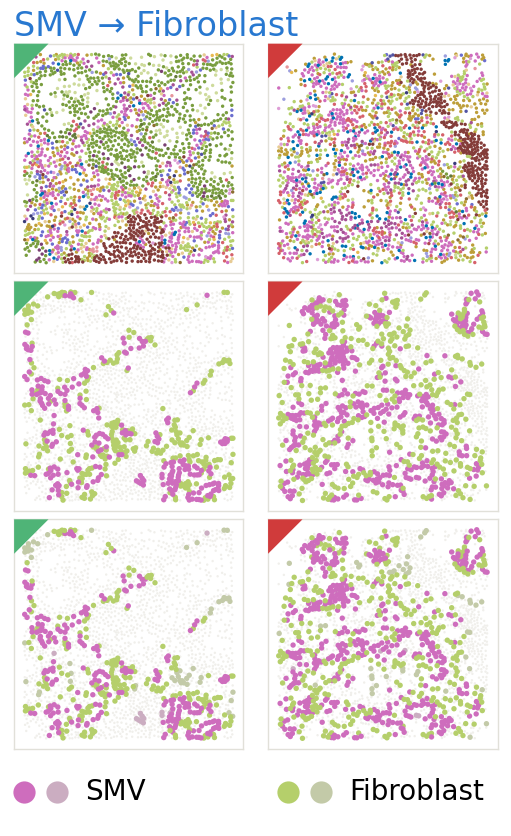

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Duodenum_Cortico_Response\cells.pdf


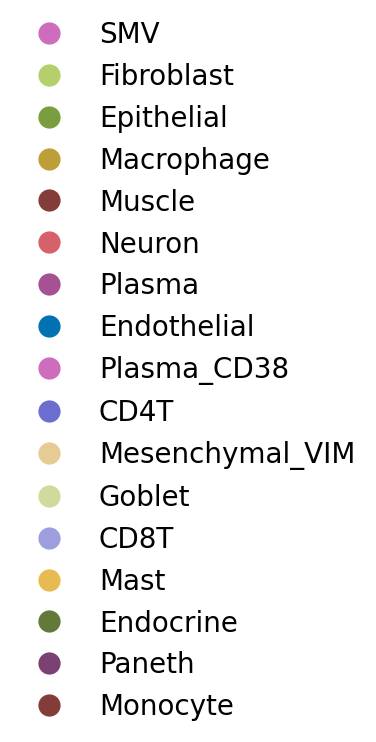

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,attracts,SMV -> Fibroblast,Responder,True,GVHD_30_FOV_2,246
1,attracts,SMV -> Fibroblast,Non-responder,False,GVHD_06_FOV_5,391


In [12]:
rule_examples("Duodenum", "Cortico Response")

### Duodenum · Days after Transplant grouped

c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\scr

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\ends_Duodenum_Days_after_Transplant_grouped.pdf


c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\scr

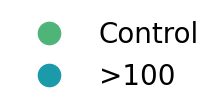

attracts_Plasma_CD38_to_Fibroblast
Control_01_FOV_4
not mined in this FOV
GVHD_27_FOV_2
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.072       0.962 1.308     0.017        7.05           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Duodenum_Days_after_Transplant_grouped\attracts_Plasma_CD38_to_Fibroblast.pdf
saved attracts_Plasma_CD38_to_Fibroblast_1, attracts_Plasma_CD38_to_Fibroblast_2, attracts_Plasma_CD38_to_Fibroblast_3, attracts_Plasma_CD38_to_Fibroblast_4, attracts_Plasma_CD38_to_Fibroblast_5, attracts_Plasma_CD38_to_Fibroblast_6, attracts_Plasma_CD38_to_Fibroblast_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Duodenum_Days_after_Transplant_grouped


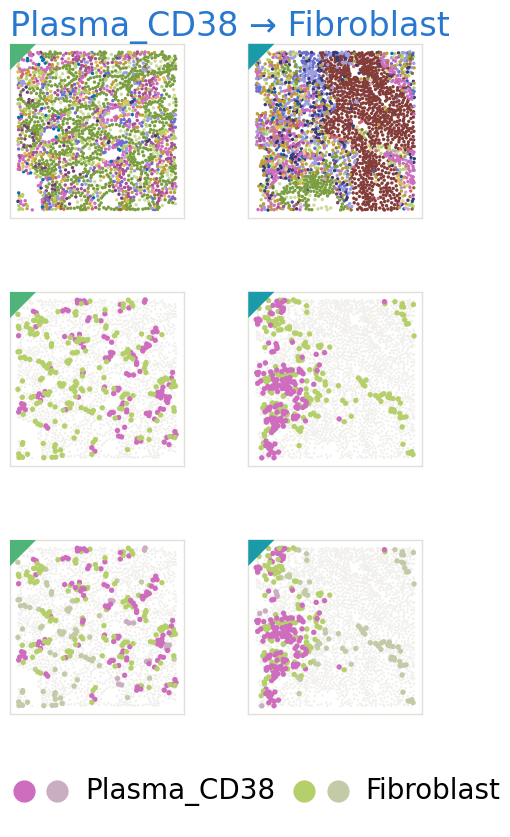

attracts_Plasma_to_Fibroblast
Control_09_FOV_1
not mined in this FOV
GVHD_34_FOV_1
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.094       0.945 1.272      0.02       4.658           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Duodenum_Days_after_Transplant_grouped\attracts_Plasma_to_Fibroblast.pdf
saved attracts_Plasma_to_Fibroblast_1, attracts_Plasma_to_Fibroblast_2, attracts_Plasma_to_Fibroblast_3, attracts_Plasma_to_Fibroblast_4, attracts_Plasma_to_Fibroblast_5, attracts_Plasma_to_Fibroblast_6, attracts_Plasma_to_Fibroblast_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Duodenum_Days_after_Transplant_grouped


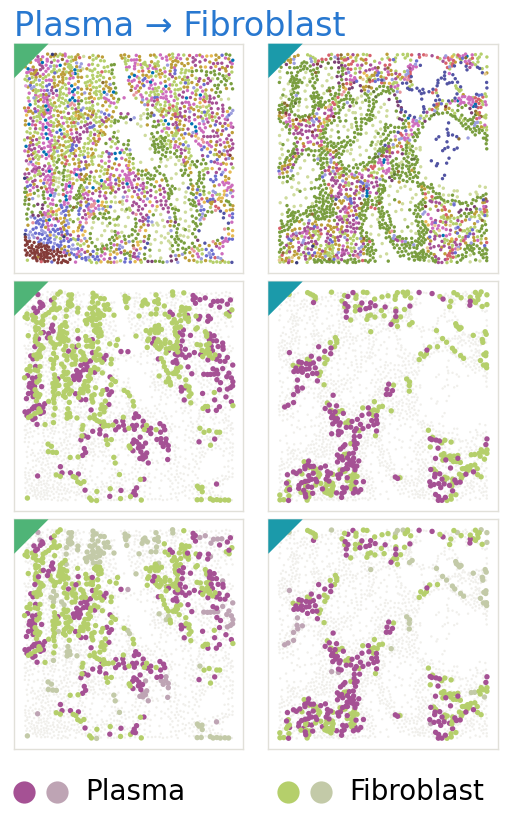

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rule_examples_FOV_vertical\Duodenum_Days_after_Transplant_grouped\cells.pdf


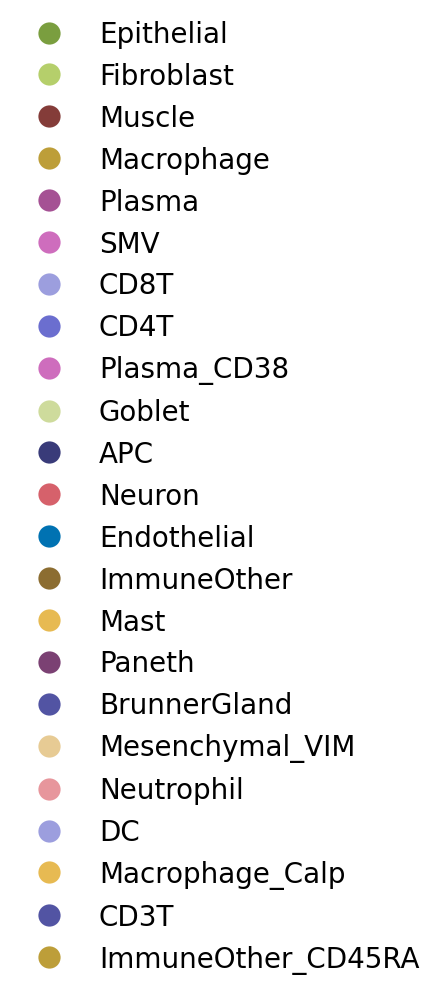

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,attracts,Plasma_CD38 -> Fibroblast,Control,False,Control_01_FOV_4,127
1,attracts,Plasma_CD38 -> Fibroblast,>100,True,GVHD_27_FOV_2,160
2,attracts,Plasma -> Fibroblast,Control,False,Control_09_FOV_1,252
3,attracts,Plasma -> Fibroblast,>100,True,GVHD_34_FOV_1,217


In [13]:
rule_examples("Duodenum", "Days after Transplant grouped")

## Stable rules

### Colon · Pathological score

c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\scr

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\ends_Colon_Pathological_score.pdf


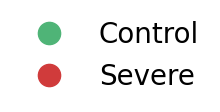

avoids_Goblet_to_Neuron
Control_Colon_01_FOV_4
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.003       0.022 0.071    -0.037       0.702            0.01
GVHD_37_FOV_4
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.033       0.315 0.539    -0.028       0.607           0.018
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Colon_Pathological_score\avoids_Goblet_to_Neuron.pdf
saved avoids_Goblet_to_Neuron_1, avoids_Goblet_to_Neuron_2, avoids_Goblet_to_Neuron_3, avoids_Goblet_to_Neuron_4, avoids_Goblet_to_Neuron_5, avoids_Goblet_to_Neuron_6, avoids_Goblet_to_Neuron_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Colon_Pathological_score


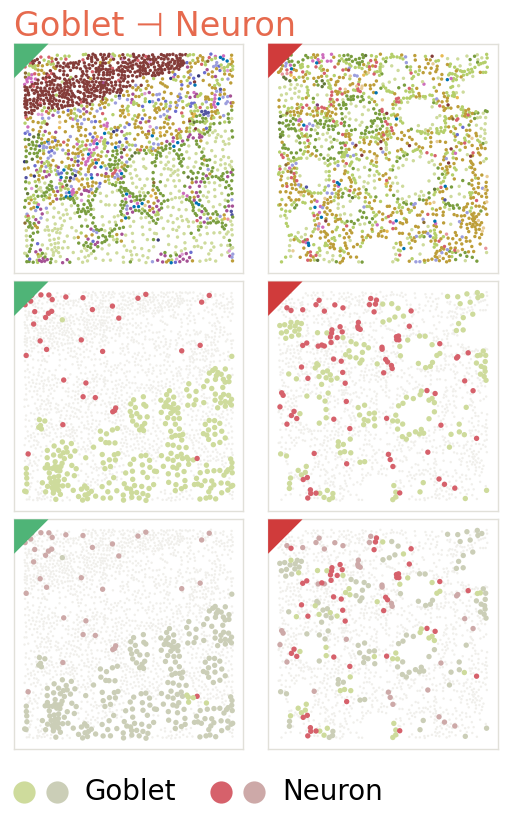

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Colon_Pathological_score\cells.pdf


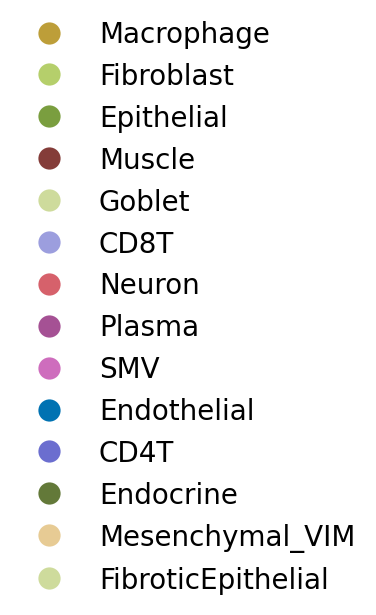

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,avoids,Goblet -> Neuron,Control,True,Control_Colon_01_FOV_4,37
1,avoids,Goblet -> Neuron,Severe,True,GVHD_37_FOV_4,85


In [14]:
rule_examples("Colon", "Pathological score", stable=True)

### Colon · Cortico Response

c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\scr

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\ends_Colon_Cortico_Response.pdf


c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\scr

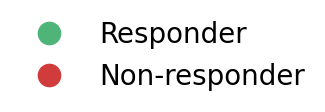

avoids_Goblet_to_SMV
GVHD_23_FOV_1
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.033       0.223 0.413    -0.047       0.591           0.005
GVHD_32_FOV_3
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.001       0.015 0.032    -0.029       0.536           0.002
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Colon_Cortico_Response\avoids_Goblet_to_SMV.pdf
saved avoids_Goblet_to_SMV_1, avoids_Goblet_to_SMV_2, avoids_Goblet_to_SMV_3, avoids_Goblet_to_SMV_4, avoids_Goblet_to_SMV_5, avoids_Goblet_to_SMV_6, avoids_Goblet_to_SMV_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Colon_Cortico_Response


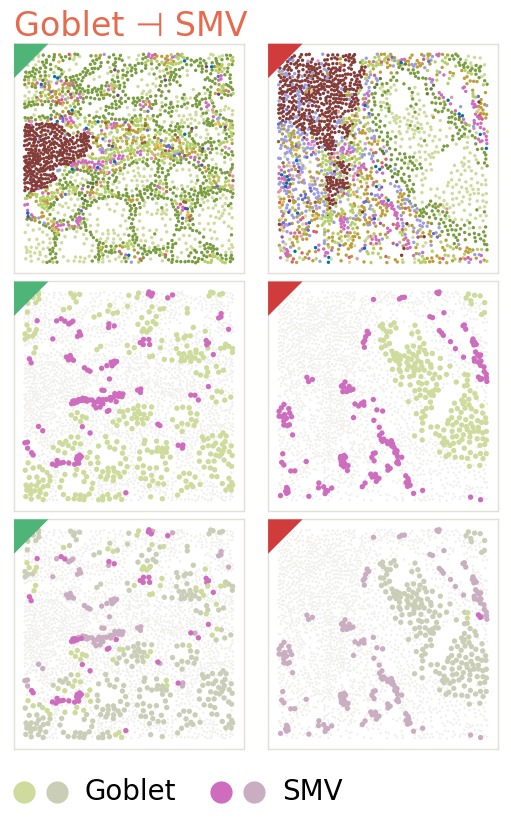

avoids_Macrophage_to_Goblet
GVHD_23_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.096       0.455 0.619    -0.059       0.487           0.005
GVHD_22_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.076       0.346 0.647    -0.041       0.712           0.004
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Colon_Cortico_Response\avoids_Macrophage_to_Goblet.pdf
saved avoids_Macrophage_to_Goblet_1, avoids_Macrophage_to_Goblet_2, avoids_Macrophage_to_Goblet_3, avoids_Macrophage_to_Goblet_4, avoids_Macrophage_to_Goblet_5, avoids_Macrophage_to_Goblet_6, avoids_Macrophage_to_Goblet_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Colon_Cortico_Response


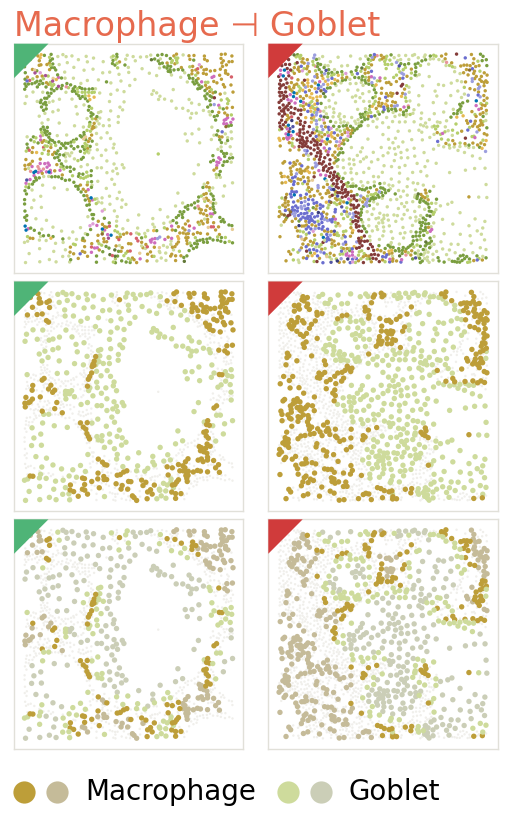

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Colon_Cortico_Response\cells.pdf


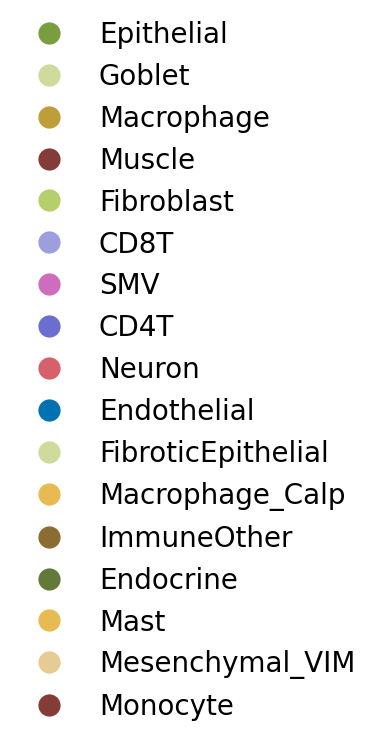

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,avoids,Goblet -> SMV,Responder,True,GVHD_23_FOV_1,124
1,avoids,Goblet -> SMV,Non-responder,True,GVHD_32_FOV_3,164
2,avoids,Macrophage -> Goblet,Responder,True,GVHD_23_FOV_2,209
3,avoids,Macrophage -> Goblet,Non-responder,True,GVHD_22_FOV_2,348


In [15]:
rule_examples("Colon", "Cortico Response", stable=True)

### Duodenum · Pathological score

c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\scr

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\ends_Duodenum_Pathological_score.pdf


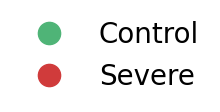

attracts_Epithelial_to_Goblet
Control_09_FOV_4
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.229        0.85 1.326     0.056       2.388           0.005
GVHD_57_FOV_4
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.407       0.749   1.2     0.068       1.498           0.005
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Pathological_score\attracts_Epithelial_to_Goblet.pdf
saved attracts_Epithelial_to_Goblet_1, attracts_Epithelial_to_Goblet_2, attracts_Epithelial_to_Goblet_3, attracts_Epithelial_to_Goblet_4, attracts_Epithelial_to_Goblet_5, attracts_Epithelial_to_Goblet_6, attracts_Epithelial_to_Goblet_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Pathological_score


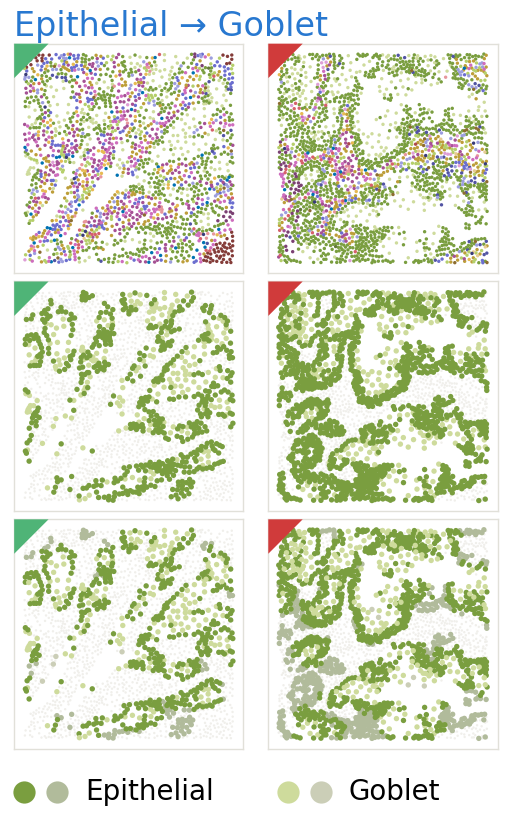

avoids_Goblet_to_SMV
Control_01_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.007       0.133 0.289    -0.017       0.622           0.004
GVHD_09_FOV_4
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.009       0.204 0.435    -0.012       0.666           0.004
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Pathological_score\avoids_Goblet_to_SMV.pdf
saved avoids_Goblet_to_SMV_1, avoids_Goblet_to_SMV_2, avoids_Goblet_to_SMV_3, avoids_Goblet_to_SMV_4, avoids_Goblet_to_SMV_5, avoids_Goblet_to_SMV_6, avoids_Goblet_to_SMV_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Pathological_score


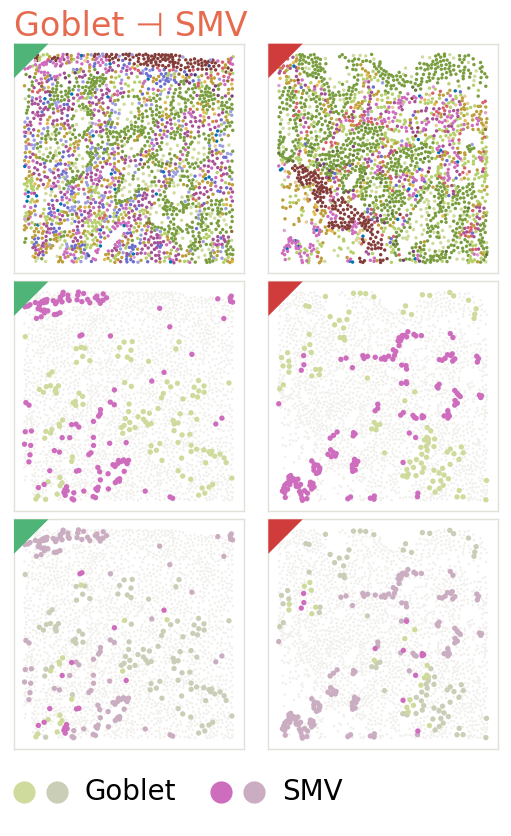

avoids_Macrophage_to_Goblet
Control_04_FOV_1
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.029       0.286 0.721    -0.011       0.845           0.005
GVHD_57_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.033       0.345 0.567    -0.025       0.598           0.005
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Pathological_score\avoids_Macrophage_to_Goblet.pdf
saved avoids_Macrophage_to_Goblet_1, avoids_Macrophage_to_Goblet_2, avoids_Macrophage_to_Goblet_3, avoids_Macrophage_to_Goblet_4, avoids_Macrophage_to_Goblet_5, avoids_Macrophage_to_Goblet_6, avoids_Macrophage_to_Goblet_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Pathological_score


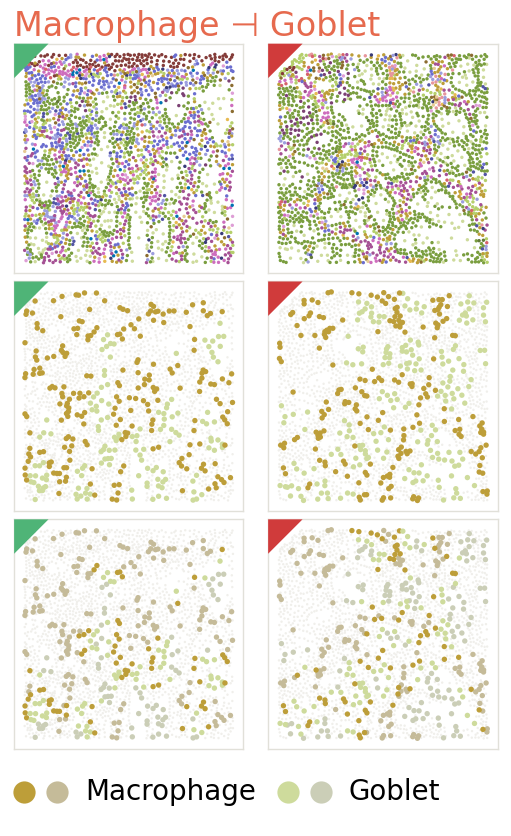

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Pathological_score\cells.pdf


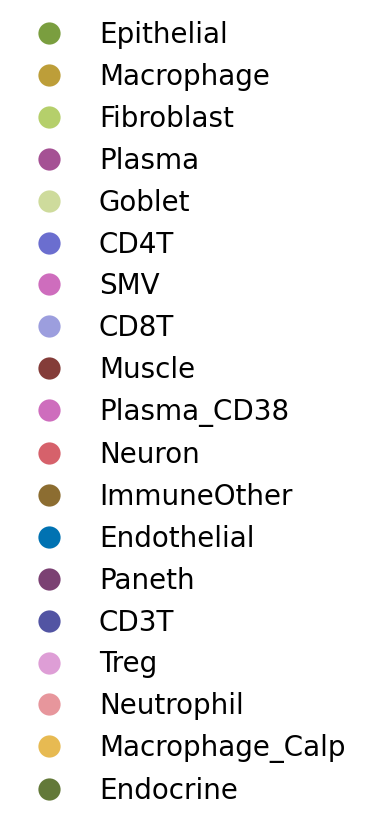

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,attracts,Epithelial -> Goblet,Control,True,Control_09_FOV_4,194
1,attracts,Epithelial -> Goblet,Severe,True,GVHD_57_FOV_4,246
2,avoids,Goblet -> SMV,Control,True,Control_01_FOV_2,120
3,avoids,Goblet -> SMV,Severe,True,GVHD_09_FOV_4,100
4,avoids,Macrophage -> Goblet,Control,True,Control_04_FOV_1,136
5,avoids,Macrophage -> Goblet,Severe,True,GVHD_57_FOV_2,199


In [16]:
rule_examples("Duodenum", "Pathological score", stable=True)

### Duodenum · Clinical score

c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\scr

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\ends_Duodenum_Clinical_score.pdf


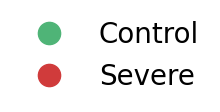

attracts_Epithelial_to_Goblet
Control_09_FOV_4
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.229        0.85 1.326     0.056       2.388           0.005
GVHD_57_FOV_4
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.407       0.749   1.2     0.068       1.498           0.005
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Clinical_score\attracts_Epithelial_to_Goblet.pdf
saved attracts_Epithelial_to_Goblet_1, attracts_Epithelial_to_Goblet_2, attracts_Epithelial_to_Goblet_3, attracts_Epithelial_to_Goblet_4, attracts_Epithelial_to_Goblet_5, attracts_Epithelial_to_Goblet_6, attracts_Epithelial_to_Goblet_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Clinical_score


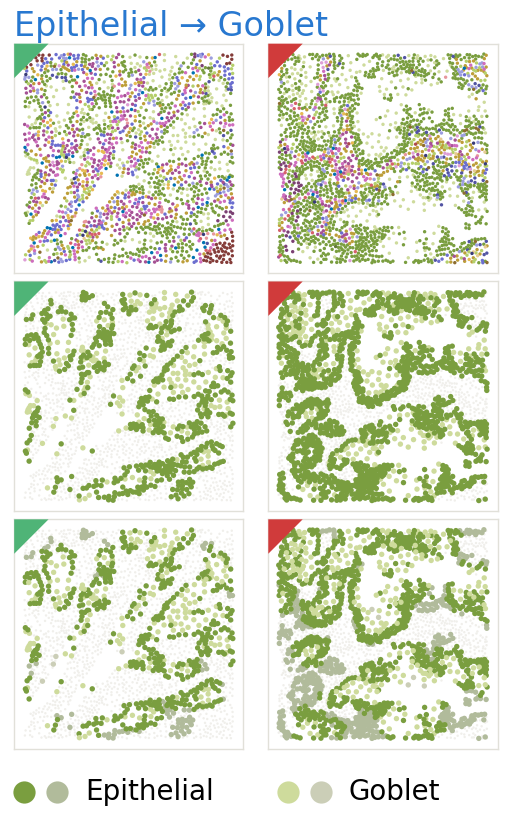

avoids_Goblet_to_SMV
Control_01_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.007       0.133 0.289    -0.017       0.622           0.004
GVHD_34_FOV_1
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.004       0.055 0.114    -0.029       0.546           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Clinical_score\avoids_Goblet_to_SMV.pdf
saved avoids_Goblet_to_SMV_1, avoids_Goblet_to_SMV_2, avoids_Goblet_to_SMV_3, avoids_Goblet_to_SMV_4, avoids_Goblet_to_SMV_5, avoids_Goblet_to_SMV_6, avoids_Goblet_to_SMV_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Clinical_score


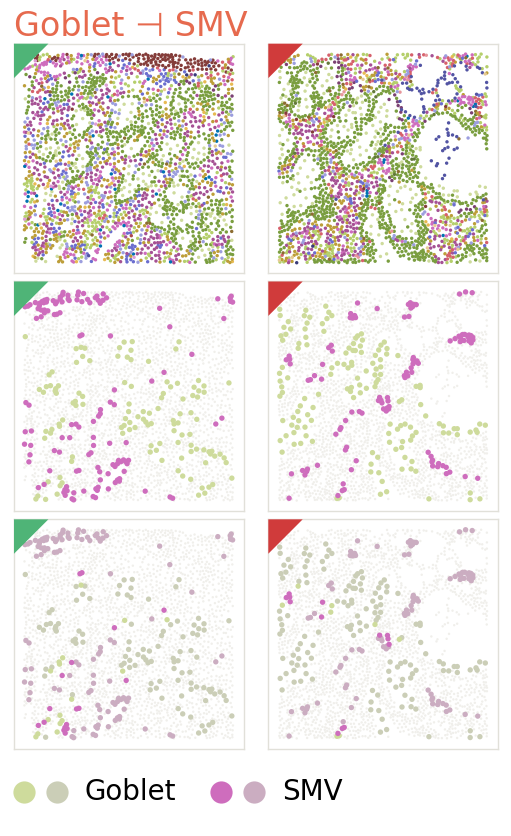

avoids_SMV_to_Goblet
Control_01_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.007       0.128  0.28    -0.019       0.624           0.004
GVHD_34_FOV_1
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.006       0.124 0.262    -0.017       0.601           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Clinical_score\avoids_SMV_to_Goblet.pdf
saved avoids_SMV_to_Goblet_1, avoids_SMV_to_Goblet_2, avoids_SMV_to_Goblet_3, avoids_SMV_to_Goblet_4, avoids_SMV_to_Goblet_5, avoids_SMV_to_Goblet_6, avoids_SMV_to_Goblet_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Clinical_score


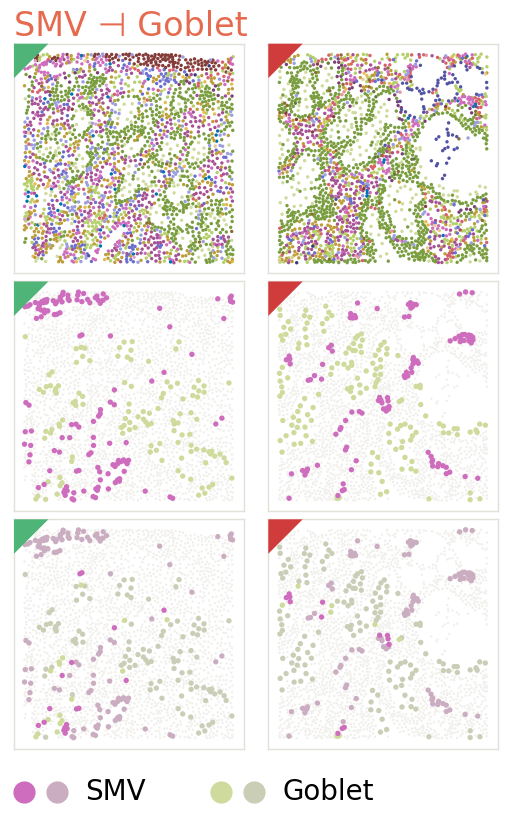

avoids_Macrophage_to_Goblet
Control_04_FOV_1
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.029       0.286 0.721    -0.011       0.845           0.005
GVHD_57_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.033       0.345 0.567    -0.025       0.598           0.005
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Clinical_score\avoids_Macrophage_to_Goblet.pdf
saved avoids_Macrophage_to_Goblet_1, avoids_Macrophage_to_Goblet_2, avoids_Macrophage_to_Goblet_3, avoids_Macrophage_to_Goblet_4, avoids_Macrophage_to_Goblet_5, avoids_Macrophage_to_Goblet_6, avoids_Macrophage_to_Goblet_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Clinical_score


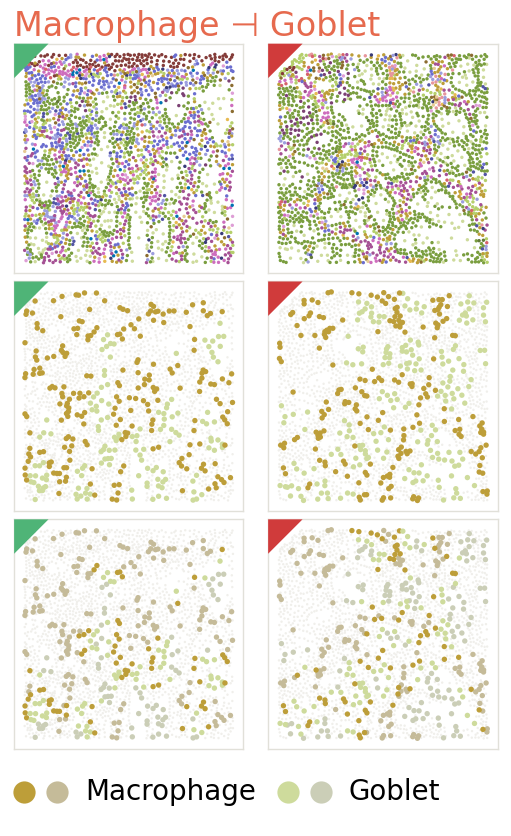

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Clinical_score\cells.pdf


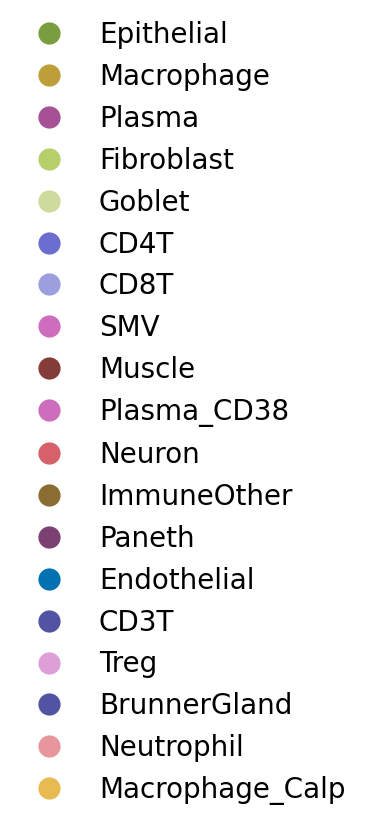

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,attracts,Epithelial -> Goblet,Control,True,Control_09_FOV_4,194
1,attracts,Epithelial -> Goblet,Severe,True,GVHD_57_FOV_4,246
2,avoids,Goblet -> SMV,Control,True,Control_01_FOV_2,120
3,avoids,Goblet -> SMV,Severe,True,GVHD_34_FOV_1,105
4,avoids,SMV -> Goblet,Control,True,Control_01_FOV_2,120
5,avoids,SMV -> Goblet,Severe,True,GVHD_34_FOV_1,105
6,avoids,Macrophage -> Goblet,Control,True,Control_04_FOV_1,136
7,avoids,Macrophage -> Goblet,Severe,True,GVHD_57_FOV_2,199


In [17]:
rule_examples("Duodenum", "Clinical score", stable=True)

### Duodenum · Cortico Response

c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\scr

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\keys\ends_Duodenum_Cortico_Response.pdf


c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Owner\Documents\scr

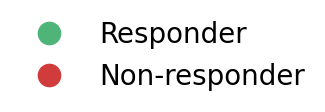

attracts_Epithelial_to_Goblet
GVHD_56_FOV_3
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.302       0.762 1.608     0.114        2.21           0.003
GVHD_57_FOV_4
    Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
attracts    0.407       0.749   1.2     0.068       1.498           0.005
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Cortico_Response\attracts_Epithelial_to_Goblet.pdf
saved attracts_Epithelial_to_Goblet_1, attracts_Epithelial_to_Goblet_2, attracts_Epithelial_to_Goblet_3, attracts_Epithelial_to_Goblet_4, attracts_Epithelial_to_Goblet_5, attracts_Epithelial_to_Goblet_6, attracts_Epithelial_to_Goblet_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Cortico_Response


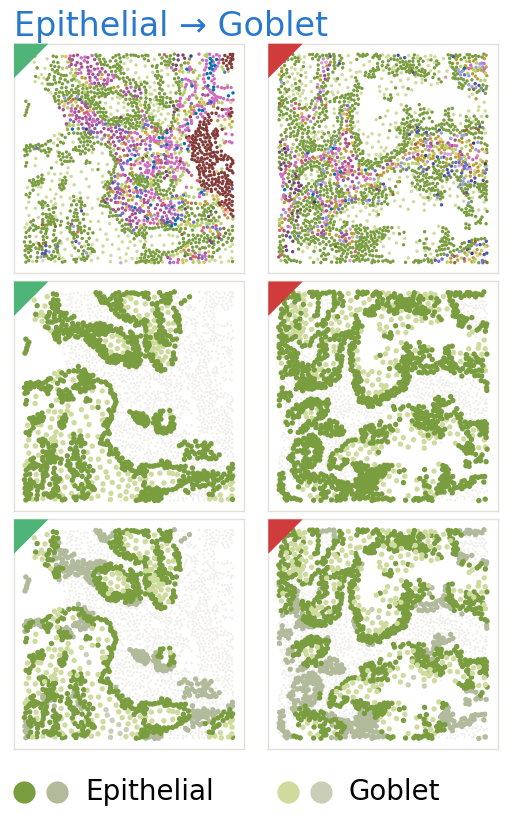

avoids_SMV_to_Goblet
GVHD_56_FOV_3
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.013       0.122 0.257    -0.039       0.599           0.003
GVHD_04_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.015       0.201 0.405    -0.022        0.63           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Cortico_Response\avoids_SMV_to_Goblet.pdf
saved avoids_SMV_to_Goblet_1, avoids_SMV_to_Goblet_2, avoids_SMV_to_Goblet_3, avoids_SMV_to_Goblet_4, avoids_SMV_to_Goblet_5, avoids_SMV_to_Goblet_6, avoids_SMV_to_Goblet_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Cortico_Response


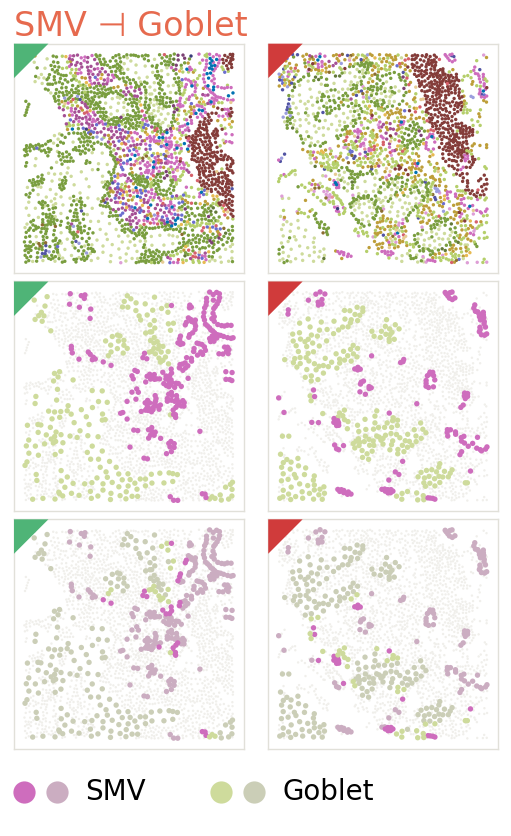

avoids_Goblet_to_CD4T
GVHD_56_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.031       0.457  0.59    -0.021       0.415           0.005
GVHD_51_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.052       0.424 0.595    -0.035       0.499           0.004
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Cortico_Response\avoids_Goblet_to_CD4T.pdf
saved avoids_Goblet_to_CD4T_1, avoids_Goblet_to_CD4T_2, avoids_Goblet_to_CD4T_3, avoids_Goblet_to_CD4T_4, avoids_Goblet_to_CD4T_5, avoids_Goblet_to_CD4T_6, avoids_Goblet_to_CD4T_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Cortico_Response


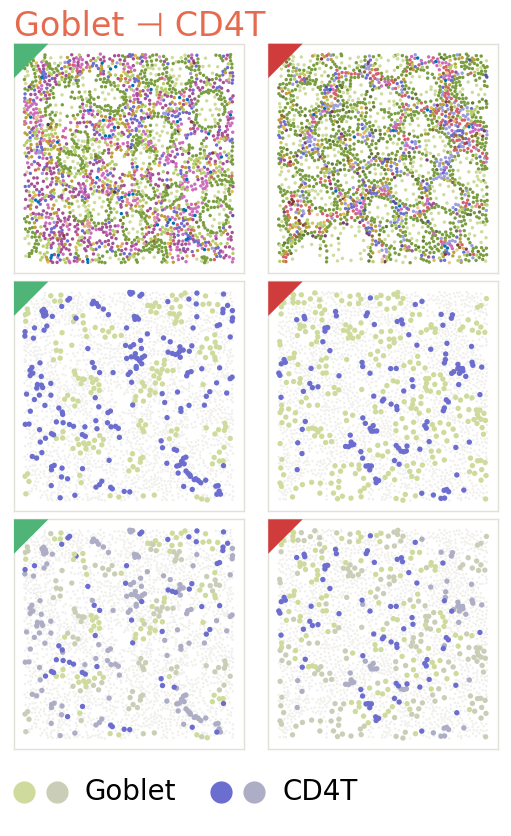

avoids_Fibroblast_to_Goblet
GVHD_56_FOV_1
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids     0.04       0.382 0.637    -0.023       0.647           0.002
GVHD_04_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.068       0.357 0.719    -0.027       0.783           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Cortico_Response\avoids_Fibroblast_to_Goblet.pdf
saved avoids_Fibroblast_to_Goblet_1, avoids_Fibroblast_to_Goblet_2, avoids_Fibroblast_to_Goblet_3, avoids_Fibroblast_to_Goblet_4, avoids_Fibroblast_to_Goblet_5, avoids_Fibroblast_to_Goblet_6, avoids_Fibroblast_to_Goblet_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Cortico_Response


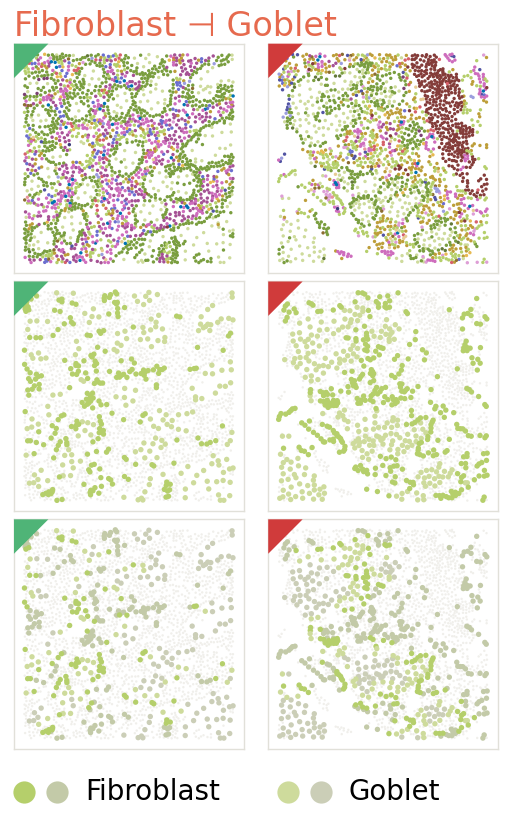

avoids_Goblet_to_SMV
GVHD_56_FOV_3
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids     0.01       0.108 0.195     -0.04       0.499           0.003
GVHD_04_FOV_2
  Kind  Support  Confidence  Lift  Leverage  Conviction  Individual_FDR
avoids    0.019       0.163 0.352    -0.036       0.642           0.003
saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Cortico_Response\avoids_Goblet_to_SMV.pdf
saved avoids_Goblet_to_SMV_1, avoids_Goblet_to_SMV_2, avoids_Goblet_to_SMV_3, avoids_Goblet_to_SMV_4, avoids_Goblet_to_SMV_5, avoids_Goblet_to_SMV_6, avoids_Goblet_to_SMV_7 in C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Cortico_Response


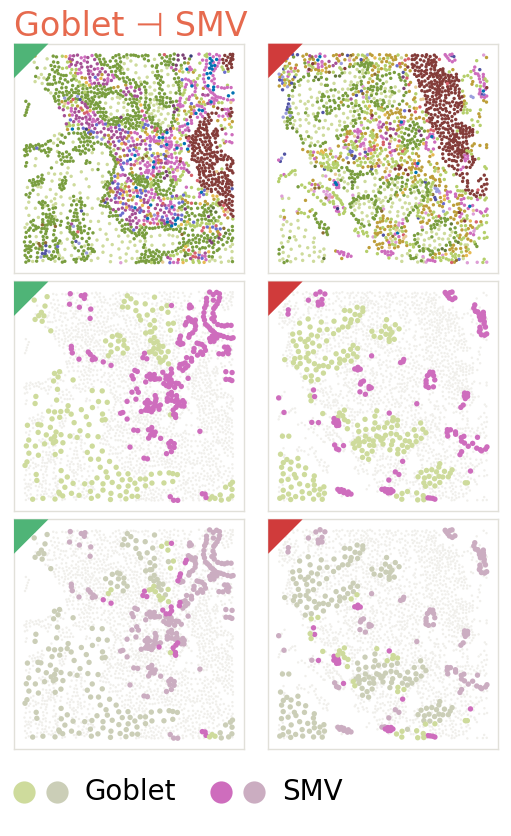

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\stable_examples_FOV_vertical\Duodenum_Cortico_Response\cells.pdf


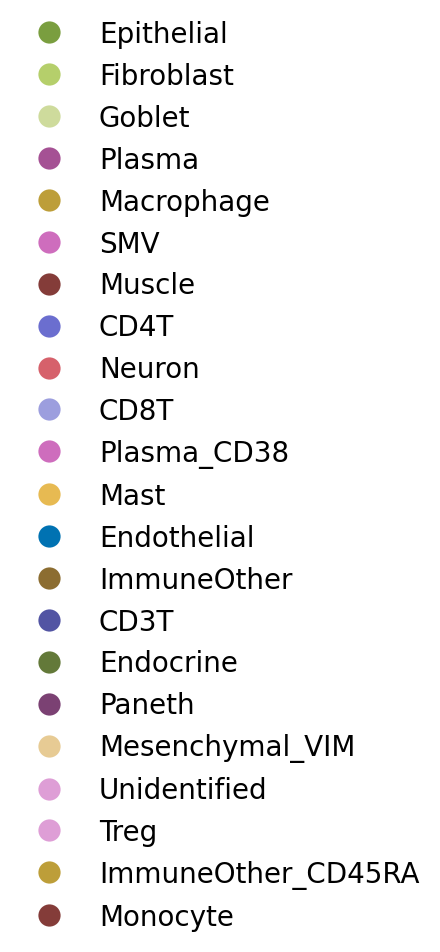

,kind,rule,group,has rule,FOV,rarer cell type's cells
0,attracts,Epithelial -> Goblet,Responder,True,GVHD_56_FOV_3,194
1,attracts,Epithelial -> Goblet,Non-responder,True,GVHD_57_FOV_4,246
2,avoids,SMV -> Goblet,Responder,True,GVHD_56_FOV_3,194
3,avoids,SMV -> Goblet,Non-responder,True,GVHD_04_FOV_2,134
4,avoids,Goblet -> CD4T,Responder,True,GVHD_56_FOV_2,166
5,avoids,Goblet -> CD4T,Non-responder,True,GVHD_51_FOV_2,128
6,avoids,Fibroblast -> Goblet,Responder,True,GVHD_56_FOV_1,176
7,avoids,Fibroblast -> Goblet,Non-responder,True,GVHD_04_FOV_2,228
8,avoids,Goblet -> SMV,Responder,True,GVHD_56_FOV_3,194
9,avoids,Goblet -> SMV,Non-responder,True,GVHD_04_FOV_2,134


In [18]:
rule_examples("Duodenum", "Cortico Response", stable=True)